# Pelacakan Objek Tunggal dengan Fusi *Optical Flow* Lucas–Kanade, Kalman Filter, dan Detektor Haar pada Sekuens OTB-100 *Dudek*

| | |
|---|---|
| **Mata kuliah** | Computer Vision — Magister Kecerdasan Artifisial, Universitas Gadjah Mada |
| **Pengajar** | Wahyono, Ph.D. |
| **Penyusun** | Elsa Aiziyah |
| **NIM** | 25/572243/PPA/07187 |
| **Tugas** | Penugasan Tutorial Object Tracking (individu) |

## Ringkasan
Notebook ini membangun satu alur (*pipeline*) pelacakan objek tunggal, mulai dari berkas video mentah sampai video hasil pelacakan, berkas lintasan (`.csv`), dan metrik evaluasi. Sekuens uji adalah **Dudek** dari *Online Tracking Benchmark* OTB-100 (Wu, Lim, & Yang, 2013): 1145 frame berskala abu-abu, berukuran 720×480, dengan kamera genggam, perubahan skala 2,1 kali, rotasi kepala, oklusi oleh tangan, dan wajah yang mendekati tepi bingkai. Sekuens ini berbeda dari sekuens contoh tutorial (MOT17-11).

Tiga metode dibandingkan pada sekuens yang sama:

* **A. LK saja:** titik fitur Shi–Tomasi dilacak dengan *Pyramidal Lucas–Kanade*, lalu kotak digeser dan diskalakan dengan transformasi kesamaan hasil RANSAC.
* **B. LK + Kalman Filter:** aliran optik diperlakukan sebagai sensor **kecepatan relatif** pada Kalman Filter *Constant Velocity*.
* **C. LK + Kalman Filter + Detektor Haar (metode usulan):** detektor wajah bawaan OpenCV, yang dijalankan tiap lima frame, menjadi sensor **posisi absolut** yang mengoreksi pergeseran (*drift*) aliran optik.

Notebook ini dapat dijalankan ulang dari awal hingga akhir (*Runtime → Run all*) tanpa pemasangan paket tambahan. Seluruh data diunduh otomatis dan diverifikasi dengan *checksum* SHA-256. Waktu eksekusi kira-kira 5–8 menit pada CPU Colab.

**Daftar isi:** 1. Persiapan · 2. Data dan studi kasus · 3. Dasar metode · 4. Implementasi · 5. Eksekusi dan evaluasi · 6. Studi ablasi dan sensitivitas · 7. Video hasil · 8. Ekspor · 9. Analisis dan kesimpulan · Referensi.

## 1. Persiapan lingkungan
Sel berikut mengimpor pustaka, menetapkan *seed* acak, dan mencatat versi perangkat lunak agar hasil dapat direproduksi. Notebook ini hanya memakai pustaka yang sudah tersedia di Google Colab (OpenCV, NumPy, Pandas, Matplotlib) dan `ffmpeg` untuk menulis video H.264. Kalman Filter ditulis langsung dengan NumPy supaya setiap persamaan dapat diperiksa.

In [1]:
import os, sys, json, time, shutil, hashlib, subprocess, urllib.request
from pathlib import Path
from dataclasses import dataclass, replace, asdict

import numpy as np
import pandas as pd
import cv2
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display

SEED = 42
np.random.seed(SEED)
cv2.setRNGSeed(SEED)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

print(f"Python   : {sys.version.split()[0]}")
print(f"OpenCV   : {cv2.__version__}")
print(f"NumPy    : {np.__version__}")
print(f"Pandas   : {pd.__version__}")
print(f"ffmpeg   : {shutil.which('ffmpeg') or 'TIDAK DITEMUKAN'}")

Python   : 3.13.16
OpenCV   : 4.14.0
NumPy    : 2.4.6
Pandas   : 2.2.3
ffmpeg   : /usr/bin/ffmpeg


In [2]:
BASE = Path("/content") if Path("/content").exists() else Path.cwd() / "content_lokal"
DATA_DIR = BASE / "data_dudek"
OUT_DIR = BASE / "keluaran_tracking"
DATA_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=True)
print("Direktori data   :", DATA_DIR)
print("Direktori keluaran:", OUT_DIR)

Direktori data   : /content/data_dudek
Direktori keluaran: /content/keluaran_tracking


## 2. Data dan studi kasus
### 2.1 Akuisisi data
Data berasal dari repositori `opencv/opencv_extra` yang memuat sekuens OTB-100 *Dudek* dalam bentuk video (`dudek.webm`) beserta berkas anotasi `gt.txt` (satu baris per frame, format `x, y, lebar, tinggi`, titik acuan pojok kiri atas). Notebook mengunduh berkas dari satu *commit* tertentu agar isinya tidak berubah, lalu memeriksa *checksum* SHA-256. Jika berkas sudah ada dan *checksum*-nya cocok, unduhan dilewati.

In [3]:
COMMIT = "697e5c3de828f3154e82f222dbe902d622bbe19a"
RAW = f"https://raw.githubusercontent.com/opencv/opencv_extra/{COMMIT}/testdata/cv/tracking/dudek"
BERKAS = {
    "dudek.webm": (f"{RAW}/data/dudek.webm",
                   "679c95a22c71e259971ccaaabf805fdba55c70e224b28eafa7536b7989c722e1"),
    "gt.txt": (f"{RAW}/gt.txt",
               "6645d041ab014a2b3b7f34ca271c1ac42d3d72a9546443c7cc9c542f772f56c4"),
}


def sha256_berkas(path: Path) -> str:
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for blok in iter(lambda: f.read(1 << 20), b""):
            h.update(blok)
    return h.hexdigest()


def unduh_terverifikasi(nama: str, url: str, sha_harapan: str, percobaan: int = 3) -> Path:
    tujuan = DATA_DIR / nama
    if tujuan.exists() and sha256_berkas(tujuan) == sha_harapan:
        print(f"[ADA]   {nama} (checksum cocok)")
        return tujuan
    for p in range(1, percobaan + 1):
        try:
            print(f"[UNDUH] {nama} (percobaan {p}/{percobaan}) ...")
            urllib.request.urlretrieve(url, tujuan)
            if sha256_berkas(tujuan) == sha_harapan:
                print(f"[OK]    {nama}: {tujuan.stat().st_size/1e6:.2f} MB, checksum cocok")
                return tujuan
            print("        checksum tidak cocok, mengulang ...")
        except Exception as e:
            print(f"        gagal: {e}")
            time.sleep(2)
    raise RuntimeError(f"Gagal mengunduh {nama} dengan checksum yang benar.")


PATH_VIDEO = unduh_terverifikasi("dudek.webm", *BERKAS["dudek.webm"])
PATH_GT = unduh_terverifikasi("gt.txt", *BERKAS["gt.txt"])

[UNDUH] dudek.webm (percobaan 1/3) ...
[OK]    dudek.webm: 5.90 MB, checksum cocok
[UNDUH] gt.txt (percobaan 1/3) ...
[OK]    gt.txt: 0.02 MB, checksum cocok


### 2.2 Pemuatan dan ringkasan data
Seluruh frame diubah menjadi citra abu-abu 8-bit dan disimpan di memori (sekitar 400 MB), sehingga setiap percobaan pada bagian selanjutnya tidak perlu membaca ulang video. Jumlah baris anotasi harus sama dengan jumlah frame.

In [4]:
cap = cv2.VideoCapture(str(PATH_VIDEO))
assert cap.isOpened(), "Video tidak dapat dibuka oleh OpenCV."
FPS = float(cap.get(cv2.CAP_PROP_FPS)) or 25.0
frames_list = []
while True:
    ok, fr = cap.read()
    if not ok:
        break
    frames_list.append(cv2.cvtColor(fr, cv2.COLOR_BGR2GRAY))
cap.release()
FRAMES = np.stack(frames_list)
del frames_list
N_FRAME, TINGGI, LEBAR = FRAMES.shape
DT = 1.0 / FPS

GT = np.loadtxt(PATH_GT, delimiter=",")          # kolom: x, y, w, h (pojok kiri-atas)
assert GT.shape == (N_FRAME, 4), f"Jumlah baris GT {GT.shape[0]} != jumlah frame {N_FRAME}"
GT_C = np.c_[GT[:, 0] + GT[:, 2] / 2, GT[:, 1] + GT[:, 3] / 2]   # centroid GT

print(f"Resolusi        : {LEBAR}x{TINGGI}")
print(f"Frame rate      : {FPS:.1f} FPS (dt = {DT:.3f} s)")
print(f"Jumlah frame    : {N_FRAME} ({N_FRAME / FPS:.1f} detik)")
print(f"Memori frame    : {FRAMES.nbytes / 1e6:.0f} MB")
kec = np.hypot(*np.diff(GT_C, axis=0).T)
print(f"Kecepatan GT    : rata-rata {kec.mean():.2f}, p95 {np.percentile(kec, 95):.2f}, maks {kec.max():.2f} px/frame")
print(f"Lebar kotak GT  : {GT[:,2].min():.0f} - {GT[:,2].max():.0f} px (rasio {GT[:,2].max()/GT[:,2].min():.2f}x)")
print(f"Tinggi kotak GT : {GT[:,3].min():.0f} - {GT[:,3].max():.0f} px")

Resolusi        : 720x480
Frame rate      : 25.0 FPS (dt = 0.040 s)
Jumlah frame    : 1145 (45.8 detik)
Memori frame    : 396 MB
Kecepatan GT    : rata-rata 2.78, p95 10.75, maks 22.36 px/frame
Lebar kotak GT  : 95 - 202 px (rasio 2.13x)
Tinggi kotak GT : 123 - 248 px


### 2.3 Karakteristik video (deskripsi studi kasus)
Gambar di bawah memperlihatkan sepuluh frame sampel. Berdasarkan pengamatan frame dan statistik anotasi, karakteristik sekuens ini sebagai berikut.

* **Jumlah target:** satu orang (wajah dan kepala), dilacak sebagai objek tunggal. Kotak awal pada frame 1 diambil dari anotasi, sesuai protokol OTB.
* **Latar belakang:** ruang kantor dengan perabot, monitor, dan rak buku. Kontras citra rendah dan citra berskala abu-abu.
* **Gerak kamera:** kamera dipegang tangan, sehingga seluruh latar bergeser dan pada beberapa bagian ikut berputar.
* **Perubahan skala dan pose:** lebar kotak anotasi berubah dari 95 sampai 202 piksel (2,1 kali). Kepala menoleh dan miring (rotasi dalam dan luar bidang citra).
* **Oklusi dan keluar bingkai:** tangan menutupi wajah di sekitar frame 204–230, tangan menyentuh kacamata di sekitar frame 357, dan wajah turun ke tepi bawah bingkai di sekitar frame 971–985.
* **Gerak cepat:** kecepatan pusat kotak mencapai 22 piksel per frame (persentil ke-95: 10,7 piksel per frame).

Metadata OTB menandai sekuens ini dengan atribut *scale variation*, *occlusion*, *deformation*, *motion blur*, *in-plane rotation*, *out-of-plane rotation*, *out-of-view*, dan *background clutter*. Kombinasi tersebut membuat sekuens ini sulit bagi pelacak yang hanya bertumpu pada aliran optik.

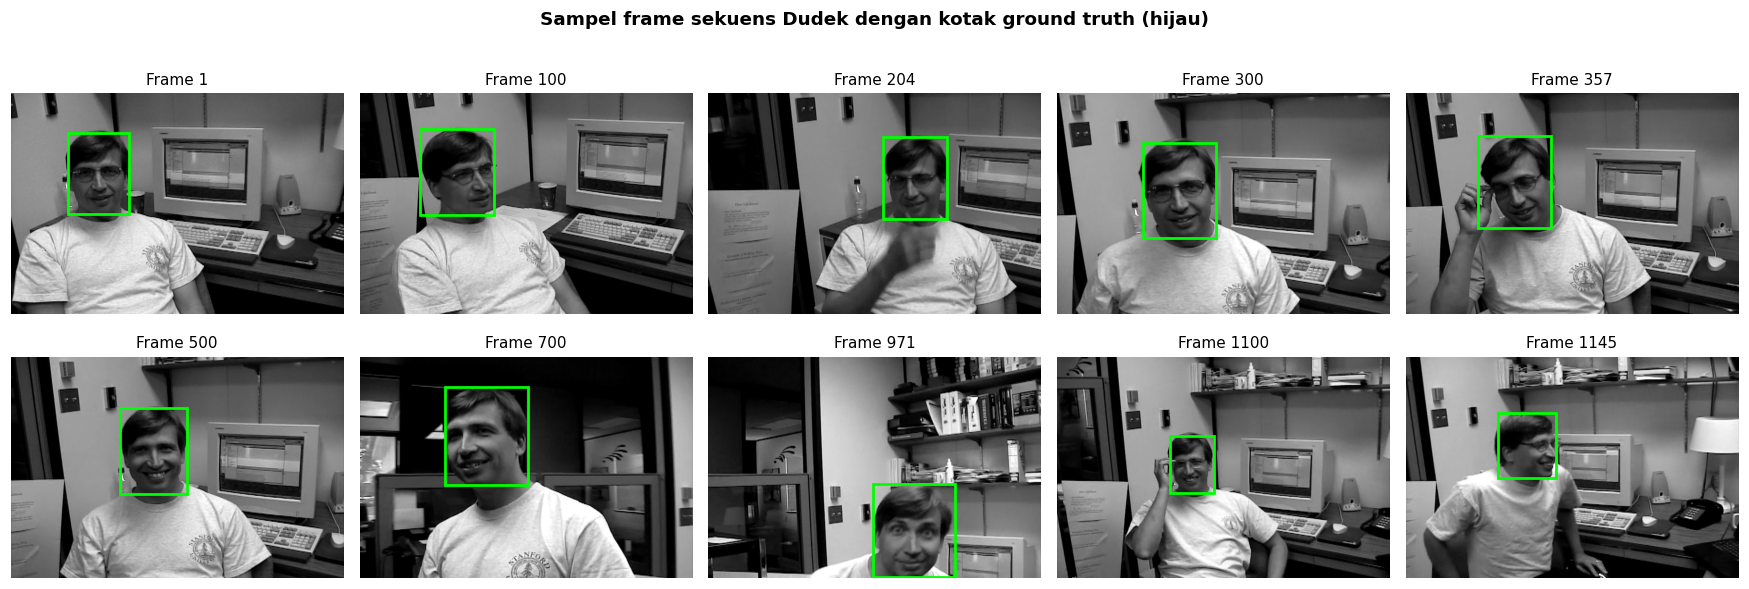

In [5]:
CONTOH = [1, 100, 204, 300, 357, 500, 700, 971, 1100, 1145]
fig, axs = plt.subplots(2, 5, figsize=(16, 5.6))
for ax, f in zip(axs.ravel(), CONTOH):
    ax.imshow(FRAMES[f - 1], cmap="gray", vmin=0, vmax=255)
    x, y, w, h = GT[f - 1]
    ax.add_patch(plt.Rectangle((x, y), w, h, fill=False, ec="lime", lw=1.8))
    ax.set_title(f"Frame {f}", fontsize=10)
    ax.axis("off")
plt.suptitle("Sampel frame sekuens Dudek dengan kotak ground truth (hijau)", y=1.0, fontweight="bold")
plt.tight_layout()
plt.savefig(OUT_DIR / "fig_sampel_dataset.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. Dasar metode
### 3.1 Optical flow Lucas–Kanade
Asumsi kekonstanan kecerahan menyatakan bahwa intensitas titik yang bergerak tidak berubah, $I(x+u,\,y+v,\,t+1)=I(x,y,t)$. Linearisasi orde pertama menghasilkan persamaan batasan aliran optik

$$I_x u + I_y v + I_t = 0 .$$

Metode Lucas–Kanade menyelesaikannya dengan kuadrat terkecil pada jendela lokal $W\times W$ yang dianggap bergerak seragam. Piramida citra (*Pyramidal LK*) memungkinkan pergeseran yang jauh lebih besar daripada jendela. Titik fitur dipilih dengan detektor sudut Shi–Tomasi pada 80% bagian tengah kotak sehingga piksel latar di tepi kotak tidak ikut terpilih.

Dua mekanisme menjaga kualitas pengukuran:

1. **Galat maju–mundur (*forward–backward*).** Setiap titik dilacak ke frame berikutnya, lalu dilacak balik. Titik dibuang jika jarak antara posisi awal dan posisi hasil pelacakan balik melebihi 1,5 piksel (Kalal dkk., 2010).
2. **Transformasi kesamaan robust.** Pasangan titik lama dan baru dicocokkan dengan model $\mathbf{p}' = s\mathbf{R}(\theta)\,\mathbf{p} + \mathbf{t}$ memakai RANSAC (`cv2.estimateAffinePartial2D`, ambang 2 piksel). Pusat kotak ditransformasikan dengan model yang sama, sedangkan lebar dan tinggi dikalikan faktor skala $s$ (dibatasi pada $[0{,}95;\,1{,}05]$ per frame).

### 3.2 Kalman Filter linear *Constant Velocity*
State $\mathbf{x}_k=[c_x,\,c_y,\,v_x,\,v_y]^\top$ (piksel dan piksel per detik) berevolusi menurut

$$\mathbf{x}_k=\mathbf{F}\mathbf{x}_{k-1}+\mathbf{w}_k,\quad \mathbf{w}_k\sim\mathcal{N}(\mathbf{0},\mathbf{Q}),\qquad
\mathbf{F}=\begin{bmatrix}\mathbf{I}_2 & \Delta t\,\mathbf{I}_2\\ \mathbf{0} & \mathbf{I}_2\end{bmatrix},\quad
\mathbf{Q}=\sigma_a^2\begin{bmatrix}\tfrac{\Delta t^4}{4}\mathbf{I}_2 & \tfrac{\Delta t^3}{2}\mathbf{I}_2\\ \tfrac{\Delta t^3}{2}\mathbf{I}_2 & \Delta t^2\,\mathbf{I}_2\end{bmatrix}.$$

$\mathbf{Q}$ disusun secara eksplisit agar urutan state $[c_x,c_y,v_x,v_y]$ tetap konsisten. Fungsi `Q_discrete_white_noise(dim=2, block_size=2)` dari FilterPy menghasilkan urutan $[c_x,v_x,c_y,v_y]$, sehingga hasilnya harus dipermutasikan terlebih dahulu bila dipakai dengan urutan state di atas.

**Prediksi:** $\hat{\mathbf{x}}_{k|k-1}=\mathbf{F}\hat{\mathbf{x}}_{k-1|k-1}$ dan $\mathbf{P}_{k|k-1}=\mathbf{F}\mathbf{P}_{k-1|k-1}\mathbf{F}^\top+\mathbf{Q}$.

**Koreksi** untuk setiap sensor dengan matriks observasi $\mathbf{H}$ dan kovarians noise $\mathbf{R}$:

$$\mathbf{S}_k=\mathbf{H}\mathbf{P}_{k|k-1}\mathbf{H}^\top+\mathbf{R},\quad
\mathbf{K}_k=\mathbf{P}_{k|k-1}\mathbf{H}^\top\mathbf{S}_k^{-1},\quad
\hat{\mathbf{x}}_{k|k}=\hat{\mathbf{x}}_{k|k-1}+\mathbf{K}_k\boldsymbol{\nu}_k,\quad \boldsymbol{\nu}_k=\mathbf{z}_k-\mathbf{H}\hat{\mathbf{x}}_{k|k-1}.$$

Kovarians diperbarui dengan bentuk Joseph, $\mathbf{P}_{k|k}=(\mathbf{I}-\mathbf{K}\mathbf{H})\mathbf{P}_{k|k-1}(\mathbf{I}-\mathbf{K}\mathbf{H})^\top+\mathbf{K}\mathbf{R}\mathbf{K}^\top$, yang menjaga $\mathbf{P}$ tetap simetris dan semi-definit positif.

**Gerbang validasi (*gating*).** Pengukuran diterima hanya bila *Normalized Innovation Squared* $\mathrm{NIS}=\boldsymbol{\nu}^\top\mathbf{S}^{-1}\boldsymbol{\nu}$ tidak melebihi kuantil distribusi $\chi^2$ dengan 2 derajat bebas (9,21 untuk 99% dan 13,82 untuk 99,9%).

### 3.3 Fusi dua sensor yang saling melengkapi
Aliran optik bersifat halus dan dapat dihitung pada setiap frame, tetapi hanya mengukur *perubahan* posisi, sehingga galatnya menumpuk (*drift*). Detektor memberi posisi *absolut* yang tidak mengalami *drift*, tetapi lebih berisik dan tidak tersedia pada setiap frame. Karena itu keduanya dimodelkan sebagai dua sensor yang berbeda:

* **Sensor kecepatan (aliran optik):** $\mathbf{z}^{v}_k=\big(\mathbf{A}_k\hat{\mathbf{c}}_{k-1|k-1}+\mathbf{t}_k-\hat{\mathbf{c}}_{k-1|k-1}\big)/\Delta t$, dengan $\mathbf{H}_v=[\mathbf{0}\;\mathbf{I}_2]$ dan $\mathbf{R}_v=\sigma_v^2\mathbf{I}_2$. Karena yang diukur adalah kecepatan, galat posisi tidak ikut tercatat sebagai informasi posisi yang "pasti".
* **Sensor posisi (detektor Haar):** $\mathbf{z}^{p}_k$ adalah pusat kotak deteksi yang dipetakan ke konvensi kotak anotasi, dengan $\mathbf{H}_p=[\mathbf{I}_2\;\mathbf{0}]$ dan $\mathbf{R}_p=\sigma_p^2\mathbf{I}_2$.

**Pemetaan kotak deteksi ke kotak anotasi.** Kotak Haar hanya menutupi wajah, sedangkan kotak anotasi mencakup kepala. Selisih pusat (relatif terhadap ukuran deteksi) dan rasio ukuran dihitung **satu kali** pada frame 1, saat kotak awal diketahui, lalu dipakai untuk semua deteksi berikutnya.

**Alur per frame (metode C):**

```
untuk setiap frame k = 2 ... N:
  1. PREDIKSI   : KF memprediksi x(k|k-1), P(k|k-1)   (kecepatan diredam 0,85 jika frame sebelumnya tanpa pengukuran)
  2. ALIRAN OPTIK: LK + cek maju-mundur + RANSAC -> transformasi kesamaan A_k
                  -> pengukuran kecepatan z_v; diterima jika lolos gerbang NIS (99%)
  3. DETEKSI    : jika k kelipatan 5 ATAU tidak ada pengukuran LK yang diterima -> Haar mendeteksi wajah
                  pilih deteksi dengan NIS terkecil;
                  jika NIS <= 13,82      -> koreksi posisi biasa
                  jika NIS lebih besar tetapi jarak <= 1 x lebar kotak
                                         -> RE-INISIALISASI posisi pada deteksi (LK dianggap gagal)
  4. UKURAN     : lebar/tinggi dikalikan faktor skala LK; saat deteksi diterima, dicampur 30% dari ukuran deteksi
  5. PENYEGARAN : jika titik LK valid < 20 atau terjadi re-inisialisasi -> cari titik Shi-Tomasi baru di kotak estimasi
```

Varian **A** memakai langkah 2 tanpa Kalman Filter. Varian **B** memakai langkah 1, 2, 4, dan 5 tanpa detektor.

## 4. Implementasi
### 4.1 Kalman Filter
Kelas berikut mengimplementasikan persamaan pada bagian 3.2. Metode `nis` menghitung jarak Mahalanobis inovasi, `update` menolak pengukuran yang melewati gerbang, dan `reinit_posisi` memulai ulang state dari satu deteksi.

In [6]:
class KalmanCV:
    """Kalman Filter linear model Constant Velocity. State x = [cx, cy, vx, vy]^T."""

    def __init__(self, c0, dt, sigma_a, sigma_p0, sigma_v0):
        self.dt = dt
        I2 = np.eye(2)
        self.H_pos = np.hstack([I2, np.zeros((2, 2))])     # mengukur posisi
        self.H_vel = np.hstack([np.zeros((2, 2)), I2])     # mengukur kecepatan
        # Kovarians noise proses: percepatan acak (white-noise acceleration), diskretisasi eksak.
        self.Q = sigma_a ** 2 * np.block([[dt ** 4 / 4 * I2, dt ** 3 / 2 * I2],
                                          [dt ** 3 / 2 * I2, dt ** 2 * I2]])
        self.P = np.diag([sigma_p0 ** 2] * 2 + [sigma_v0 ** 2] * 2).astype(float)
        self.x = np.array([c0[0], c0[1], 0.0, 0.0])

    def F(self, lam=1.0):
        """Matriks transisi; lam < 1 meredam kecepatan saat tanpa pengukuran."""
        dt = self.dt
        return np.array([[1, 0, dt, 0], [0, 1, 0, dt], [0, 0, lam, 0], [0, 0, 0, lam]], float)

    def predict(self, lam=1.0):
        F = self.F(lam)
        self.x = F @ self.x
        self.P = F @ self.P @ F.T + self.Q

    def nis(self, z, H, R):
        """Normalized Innovation Squared: v^T S^-1 v (kriteria gerbang Mahalanobis)."""
        v = z - H @ self.x
        S = H @ self.P @ H.T + R
        return float(v @ np.linalg.solve(S, v))

    def update(self, z, H, R, gerbang=None):
        """Koreksi. Mengembalikan (diterima, NIS). Pengukuran ditolak jika NIS > gerbang."""
        v = z - H @ self.x
        S = H @ self.P @ H.T + R
        nis = float(v @ np.linalg.solve(S, v))
        if gerbang is not None and nis > gerbang:
            return False, nis
        K = self.P @ H.T @ np.linalg.inv(S)
        self.x = self.x + K @ v
        IKH = np.eye(4) - K @ H
        self.P = IKH @ self.P @ IKH.T + K @ R @ K.T       # bentuk Joseph (menjaga P simetris & PSD)
        return True, nis

    def reinit_posisi(self, z, sigma_z, sigma_v0):
        """Memulai ulang state dari satu deteksi (posisi = z, kecepatan tidak diketahui)."""
        self.x = np.array([z[0], z[1], 0.0, 0.0])
        self.P = np.diag([sigma_z ** 2] * 2 + [sigma_v0 ** 2] * 2).astype(float)

### 4.2 Pelacak aliran optik
`LKFlow` mencari sudut Shi–Tomasi, melacaknya dengan *Pyramidal Lucas–Kanade* maju dan mundur, membuang titik yang tidak konsisten, lalu mengestimasi transformasi kesamaan dengan RANSAC. Kelas ini tidak menyimpan kotak; posisi pusat disuplai oleh pemanggil sehingga satu-satunya sumber posisi tetap berada pada Kalman Filter.

In [7]:
class LKFlow:
    """Shi-Tomasi + Pyramidal Lucas-Kanade + cek maju-mundur + transformasi kesamaan (RANSAC)."""

    def __init__(self, max_corners=100, quality=0.01, min_dist=5, block=5, inner=0.8,
                 win=(21, 21), levels=3, fb_thresh=1.5, min_pts=6, ransac=2.0,
                 scale_clip=(0.95, 1.05)):
        self.fp = dict(maxCorners=max_corners, qualityLevel=quality,
                       minDistance=min_dist, blockSize=block)
        self.lk = dict(winSize=win, maxLevel=levels,
                       criteria=(cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, 30, 0.01))
        self.inner, self.fb_thresh, self.min_pts = inner, fb_thresh, min_pts
        self.ransac, self.scale_clip = ransac, scale_clip
        self.prev, self.pts = None, None

    def seed(self, gray, box_c):
        """Mencari sudut Shi-Tomasi pada 'inner' x bagian tengah kotak (cx, cy, w, h)."""
        cx, cy, w, h = box_c
        H, W = gray.shape[:2]
        x1 = int(round(max(0, cx - w * self.inner / 2)))
        x2 = int(round(min(W, cx + w * self.inner / 2)))
        y1 = int(round(max(0, cy - h * self.inner / 2)))
        y2 = int(round(min(H, cy + h * self.inner / 2)))
        self.prev = gray
        if x2 - x1 < 8 or y2 - y1 < 8:
            self.pts = None
            return 0
        c = cv2.goodFeaturesToTrack(gray[y1:y2, x1:x2], **self.fp)
        if c is None or len(c) < self.min_pts:
            self.pts = None
            return 0
        c[:, 0, 0] += x1
        c[:, 0, 1] += y1
        self.pts = c
        return len(c)

    def update(self, gray):
        """Melacak titik ke frame baru. Mengembalikan dict: A (2x3), scale, n, old, new."""
        out = dict(A=None, scale=np.nan, n=0, old=np.empty((0, 2)), new=np.empty((0, 2)))
        if self.prev is None or self.pts is None or len(self.pts) < self.min_pts:
            self.prev, self.pts = gray, None
            return out
        nxt, s1, _ = cv2.calcOpticalFlowPyrLK(self.prev, gray, self.pts, None, **self.lk)
        if nxt is None:
            self.prev, self.pts = gray, None
            return out
        back, s2, _ = cv2.calcOpticalFlowPyrLK(gray, self.prev, nxt, None, **self.lk)
        fb = np.linalg.norm(self.pts - back, axis=2).ravel()                  # galat maju-mundur
        ok = (s1.ravel() == 1) & (s2.ravel() == 1) & (fb < self.fb_thresh)
        H, W = gray.shape[:2]
        p0, p1 = self.pts.reshape(-1, 2)[ok], nxt.reshape(-1, 2)[ok]
        dalam = (p1[:, 0] >= 0) & (p1[:, 0] < W) & (p1[:, 1] >= 0) & (p1[:, 1] < H)
        p0, p1 = p0[dalam], p1[dalam]
        self.prev = gray
        if len(p1) < self.min_pts:
            self.pts = None
            return out
        A, inl = cv2.estimateAffinePartial2D(p0, p1, method=cv2.RANSAC,
                                             ransacReprojThreshold=self.ransac)
        if A is None or inl is None or int(inl.sum()) < self.min_pts:
            self.pts = None
            return out
        inl = inl.ravel().astype(bool)
        s = float(np.sqrt(abs(np.linalg.det(A[:, :2]))))                      # faktor skala
        out.update(A=A, scale=float(np.clip(s, *self.scale_clip)), n=int(inl.sum()),
                   old=p0[inl], new=p1[inl])
        self.pts = p1[inl].reshape(-1, 1, 2)
        return out

### 4.3 Detektor wajah
Detektor yang dipakai adalah *Haar Cascade* wajah frontal bawaan OpenCV (Viola & Jones, 2001) pada citra yang histogramnya diekualisasi. Detektor ini bersifat deterministik, sehingga hasil deteksi seluruh frame dihitung **sekali** dan disimpan. Percobaan ablasi di bagian 6 memakai cache yang sama; jumlah panggilan detektor yang dihitung pada setiap varian tetap mengikuti jadwal deteksinya, bukan cache.

In [8]:
class DetektorHaar:
    """Detektor wajah frontal Haar Cascade (bawaan OpenCV) pada citra yang diekualisasi histogramnya."""

    def __init__(self, scale=1.1, tetangga=5, ukuran_min=(60, 60)):
        self.c = cv2.CascadeClassifier(cv2.data.haarcascades + "haarcascade_frontalface_default.xml")
        assert not self.c.empty(), "Berkas cascade tidak ditemukan."
        self.kw = dict(scaleFactor=scale, minNeighbors=tetangga, minSize=ukuran_min)

    def deteksi(self, gray):
        d = self.c.detectMultiScale(cv2.equalizeHist(gray), **self.kw)
        return [tuple(float(v) for v in r) for r in d]                        # (x, y, w, h)

### 4.4 Konfigurasi
Seluruh hiperparameter dikumpulkan dalam satu kelas data yang tidak dapat diubah (*frozen*), sehingga setiap varian percobaan didefinisikan sebagai salinan dengan beberapa nilai yang diubah. Pilihan nilai awal sebagai berikut.

* $\sigma_a = 2500$ px/s² dipilih besar dan konservatif karena gerak kepala bersifat meledak-ledak (*bursty*). Dampaknya pada konsistensi filter dibahas di bagian 6.3.
* $\sigma_v = 30$ px/s setara dengan kira-kira 1,2 piksel per frame untuk galat kecepatan aliran optik, dan $\sigma_p = 10$ px untuk galat posisi detektor.
* Gerbang 99% untuk aliran optik dan 99,9% untuk detektor. Detektor memakai gerbang yang lebih longgar karena ia berfungsi sebagai pengoreksi *drift*.
* Parameter tidak disetel langsung terhadap metrik; kepekaannya terhadap $\sigma_a$ dan $\sigma_v$ diuji pada bagian 6.3.

In [9]:
@dataclass(frozen=True)
class Konfigurasi:
    # --- komponen yang diaktifkan
    pakai_kf: bool = True            # False -> LK saja (garis dasar A)
    pakai_lk: bool = True            # False -> tanpa optical flow
    interval_deteksi: int = 5        # 0 = detektor tidak dipakai; k = setiap k frame
    # --- Kalman Filter (satuan: piksel dan detik)
    sigma_a: float = 2500.0          # simpangan baku percepatan acak [px/s^2]
    sigma_v: float = 30.0            # noise pengukuran kecepatan dari optical flow [px/s]
    sigma_det: float = 10.0          # noise pengukuran posisi dari detektor [px]
    sigma_p0: float = 3.0            # ketidakpastian posisi awal [px]
    sigma_v0: float = 100.0          # ketidakpastian kecepatan awal [px/s]
    redaman: float = 0.85            # faktor peredam kecepatan per frame saat tanpa pengukuran
    gerbang_lk: float = 9.210        # batas NIS pengukuran LK   (chi-kuadrat 2 dof, 99%)
    gerbang_det: float = 13.816      # batas NIS pengukuran deteksi (chi-kuadrat 2 dof, 99,9%)
    gamma_reinit: float = 1.0        # radius re-inisialisasi (x lebar kotak); 0 = nonaktif
    # --- optical flow
    refresh_titik: int = 20          # seed ulang titik fitur jika titik valid < nilai ini
    seed_saat_deteksi: bool = False  # True = seed ulang di setiap deteksi diterima (varian C')
    # --- ukuran kotak
    ema_ukuran: float = 0.3          # bobot ukuran dari deteksi pada pembaruan ukuran
    batas_ukuran: tuple = (0.25, 4.0)  # rentang ukuran relatif terhadap ukuran awal


CFG_C = Konfigurasi()                                              # metode usulan (final)
CFG_A = Konfigurasi(pakai_kf=False, interval_deteksi=0)            # A: LK saja
CFG_B = Konfigurasi(interval_deteksi=0)                            # B: LK + KF
print(CFG_C)

Konfigurasi(pakai_kf=True, pakai_lk=True, interval_deteksi=5, sigma_a=2500.0, sigma_v=30.0, sigma_det=10.0, sigma_p0=3.0, sigma_v0=100.0, redaman=0.85, gerbang_lk=9.21, gerbang_det=13.816, gamma_reinit=1.0, refresh_titik=20, seed_saat_deteksi=False, ema_ukuran=0.3, batas_ukuran=(0.25, 4.0))


### 4.5 Kalibrasi detektor dan cache deteksi
Pemetaan kotak deteksi ke konvensi kotak anotasi dihitung dari frame 1. Hanya kotak awal yang dipakai, sama dengan informasi yang diberikan kepada pelacak lain pada protokol OTB.

In [10]:
t0 = time.time()
DETEKTOR = DetektorHaar()
DETEKSI = [DETEKTOR.deteksi(FRAMES[i]) for i in range(N_FRAME)]   # cache; deterministik
print(f"Deteksi untuk {N_FRAME} frame selesai dalam {time.time() - t0:.1f} detik")
print(f"Frame dengan >= 1 deteksi: {np.mean([len(d) > 0 for d in DETEKSI]) * 100:.1f}%")


def kalibrasi_detektor(deteksi_f0, gt0):
    """Menghitung pemetaan kotak deteksi -> konvensi kotak GT dari kotak inisialisasi (frame 1)."""
    x, y, w, h = gt0
    c0 = np.array([x + w / 2, y + h / 2])
    d = min(deteksi_f0, key=lambda r: np.hypot(r[0] + r[2] / 2 - c0[0], r[1] + r[3] / 2 - c0[1]))
    offset = np.array([(c0[0] - (d[0] + d[2] / 2)) / d[2], (c0[1] - (d[1] + d[3] / 2)) / d[3]])
    rasio = np.array([w / d[2], h / d[3]])
    return offset, rasio


assert len(DETEKSI[0]) > 0, "Detektor tidak menemukan wajah pada frame 1."
OFFSET, RASIO = kalibrasi_detektor(DETEKSI[0], GT[0])
print(f"Offset pusat (relatif ukuran deteksi): {np.round(OFFSET, 3)} | rasio ukuran (GT/deteksi): {np.round(RASIO, 3)}")

Deteksi untuk 1145 frame selesai dalam 92.6 detik
Frame dengan >= 1 deteksi: 95.4%
Offset pusat (relatif ukuran deteksi): [ 0.01  -0.111] | rasio ukuran (GT/deteksi): [0.886 1.181]


### 4.6 Uji sanity Kalman Filter
Sebelum dipakai pada video, implementasi diuji pada data sintetis yang dibangkitkan tepat dari model yang diasumsikan filter. Dua kriteria diperiksa: (1) estimasi posisi harus lebih akurat daripada pengukuran mentah, dan (2) *Normalized Estimation Error Squared* (NEES) rata-rata harus mendekati dimensi state, yaitu 4. Matriks $\mathbf{Q}$ juga diperiksa simetris, semi-definit positif, dan tanpa kopling antar sumbu $x$ dan $y$.

In [11]:
def uji_sanity_kf(n=3000, sigma_a=2500.0, sigma_z=5.0, seed=SEED):
    """Memeriksa implementasi KF pada data sintetis dengan kebenaran dasar (ground truth) yang diketahui."""
    rng = np.random.default_rng(seed)
    kf = KalmanCV([0.0, 0.0], DT, sigma_a, sigma_z, 100.0)
    Lq = np.linalg.cholesky(kf.Q + 1e-12 * np.eye(4))
    # (1) sifat matriks proses
    eig = np.linalg.eigvalsh(kf.Q)
    assert np.allclose(kf.Q, kf.Q.T) and eig.min() > -1e-9, "Q harus simetris dan semi-definit positif"
    assert kf.Q[0, 1] == 0 and kf.Q[2, 3] == 0, "Tidak boleh ada kopling antar sumbu x dan y pada Q"
    # (2) simulasi: x_{k+1} = F x_k + w,  w ~ N(0, Q);  z = posisi + N(0, sigma_z^2)
    x = np.array([0.0, 0.0, 120.0, -80.0])
    kf.x = x + rng.multivariate_normal(np.zeros(4), kf.P)
    R = sigma_z ** 2 * np.eye(2)
    err_kf, err_ukur, nees = [], [], []
    for k in range(n):
        x = kf.F() @ x + Lq @ rng.standard_normal(4)
        z = x[:2] + sigma_z * rng.standard_normal(2)
        kf.predict()
        kf.update(z, kf.H_pos, R)
        e = x - kf.x
        err_kf.append(np.hypot(*e[:2]))
        err_ukur.append(np.hypot(*(z - x[:2])))
        nees.append(float(e @ np.linalg.solve(kf.P, e)))
    return (float(np.sqrt(np.mean(np.square(err_kf)))), float(np.sqrt(np.mean(np.square(err_ukur)))),
            float(np.mean(nees[200:])))


rmse_kf, rmse_ukur, nees_rata = uji_sanity_kf()
print(f"RMSE posisi pengukuran mentah : {rmse_ukur:6.2f} px")
print(f"RMSE posisi estimasi KF       : {rmse_kf:6.2f} px")
print(f"NEES rata-rata (ideal = 4)    : {nees_rata:6.2f}")
assert rmse_kf < rmse_ukur, "KF seharusnya menurunkan galat dibanding pengukuran mentah"
assert 3.5 < nees_rata < 4.5, "NEES tidak konsisten dengan dimensi state (4)"
print("Uji sanity Kalman Filter: LULUS")

RMSE posisi pengukuran mentah :   7.10 px
RMSE posisi estimasi KF       :   5.99 px
NEES rata-rata (ideal = 4)    :   4.06
Uji sanity Kalman Filter: LULUS


### 4.7 Fungsi pelacakan utama dan metrik
`jalankan_tracker` menjalankan alur pada bagian 3.3 untuk seluruh sekuens. Fungsi ini mengembalikan tabel hasil per frame (posisi, kecepatan, ukuran, mode, jumlah titik LK, nilai NIS), titik fitur untuk visualisasi, dan jumlah panggilan detektor.

Evaluasi mengikuti protokol OTB (Wu dkk., 2013):

* ***Center Location Error*** $\mathrm{CLE}_k=\lVert\hat{\mathbf{c}}_k-\mathbf{c}^{gt}_k\rVert_2$ dan RMSE-nya sepanjang sekuens.
* **Presisi** pada ambang 20 piksel, yaitu proporsi frame dengan $\mathrm{CLE}\le 20$ px.
* **Kurva keberhasilan:** proporsi frame dengan $\mathrm{IoU}>\tau$ untuk $\tau\in[0,1]$. **AUC** kurva ini (rata-rata atas 101 ambang) menjadi skor keberhasilan.

In [12]:
MODE_URUT = ["INIT", "LK", "LK+DET", "DET", "REINIT", "PREDIKSI", "HILANG"]


def jalankan_tracker(cfg: Konfigurasi, simpan_titik: bool = False):
    """Menjalankan seluruh sekuens. Mengembalikan (DataFrame hasil, daftar titik LK per frame, jumlah panggilan detektor)."""
    x0, y0, w0, h0 = GT[0]                                     # protokol OTB: kotak awal diberikan
    c0 = np.array([x0 + w0 / 2, y0 + h0 / 2])
    ukuran0 = np.array([w0, h0], float)
    ukuran = ukuran0.copy()
    kf = KalmanCV(c0, DT, cfg.sigma_a, cfg.sigma_p0, cfg.sigma_v0)
    lk = LKFlow()
    pos = c0.copy()                                             # dipakai bila pakai_kf = False
    lk.seed(FRAMES[0], (c0[0], c0[1], w0, h0))
    R_lk = cfg.sigma_v ** 2 * np.eye(2)
    R_det = cfg.sigma_det ** 2 * np.eye(2)
    coast, n_det_dipanggil = 0, 0
    rek, titik = [], []

    def catat(i, mode, n_lk, nis_lk, nis_det, det_dipanggil, reseed):
        c = kf.x[:2] if cfg.pakai_kf else pos
        sp = float(np.sqrt(np.trace(kf.P[:2, :2]) / 2)) if cfg.pakai_kf else np.nan
        rek.append(dict(frame=i + 1, t=i * DT, cx=c[0], cy=c[1],
                        vx=kf.x[2] if cfg.pakai_kf else np.nan, vy=kf.x[3] if cfg.pakai_kf else np.nan,
                        w=ukuran[0], h=ukuran[1], mode=mode, n_lk=n_lk, nis_lk=nis_lk,
                        nis_det=nis_det, det_dipanggil=det_dipanggil, reseed=reseed, sigma_pos=sp))

    catat(0, "INIT", 0, np.nan, np.nan, False, True)
    titik.append((np.empty((0, 2)), np.empty((0, 2))))

    for i in range(1, N_FRAME):
        g = FRAMES[i]
        prev = (kf.x[:2] if cfg.pakai_kf else pos).copy()
        if cfg.pakai_kf:
            kf.predict(cfg.redaman if coast > 0 else 1.0)

        # ---- 1) Optical flow: pengukuran KECEPATAN relatif
        res = lk.update(g) if cfg.pakai_lk else dict(A=None, n=0, scale=np.nan,
                                                      old=np.empty((0, 2)), new=np.empty((0, 2)))
        acc_lk, nis_lk = False, np.nan
        if res["A"] is not None:
            A = res["A"]
            baru = A[:, :2] @ prev + A[:, 2]                    # pusat kotak setelah transformasi kesamaan
            delta = baru - prev
            if cfg.pakai_kf:
                acc_lk, nis_lk = kf.update(delta / DT, kf.H_vel, R_lk, cfg.gerbang_lk)
            else:
                pos = baru
                acc_lk = True
            if acc_lk:
                ukuran = np.clip(ukuran * res["scale"], cfg.batas_ukuran[0] * ukuran0, cfg.batas_ukuran[1] * ukuran0)

        # ---- 2) Detektor: pengukuran POSISI absolut (terjadwal, atau saat LK gagal)
        acc_det, reinit, nis_det, det_dipanggil = False, False, np.nan, False
        jadwal = cfg.interval_deteksi > 0 and (i % cfg.interval_deteksi == 0 or (cfg.pakai_lk and not acc_lk))
        if cfg.pakai_kf and jadwal:
            det_dipanggil = True
            n_det_dipanggil += 1
            cand = []
            for (dx, dy, dw, dh) in DETEKSI[i]:
                z = np.array([dx + dw / 2 + OFFSET[0] * dw, dy + dh / 2 + OFFSET[1] * dh])
                cand.append((kf.nis(z, kf.H_pos, R_det), z, (dw * RASIO[0], dh * RASIO[1])))
            if cand:
                n, z, uk_det = min(cand, key=lambda t: t[0])
                nis_det = n
                if n <= cfg.gerbang_det:
                    kf.update(z, kf.H_pos, R_det, None)
                    acc_det = True
                elif cfg.gamma_reinit > 0 and np.hypot(*(z - kf.x[:2])) <= cfg.gamma_reinit * ukuran[0]:
                    kf.reinit_posisi(z, cfg.sigma_det, cfg.sigma_v0)   # LK dianggap gagal; percaya deteksi
                    acc_det, reinit = True, True
                if acc_det:
                    ukuran = np.clip((1 - cfg.ema_ukuran) * ukuran + cfg.ema_ukuran * np.array(uk_det),
                                     cfg.batas_ukuran[0] * ukuran0, cfg.batas_ukuran[1] * ukuran0)

        coast = 0 if (acc_lk or acc_det) else coast + 1
        if reinit:
            mode = "REINIT"
        elif acc_lk and acc_det:
            mode = "LK+DET"
        elif acc_lk:
            mode = "LK"
        elif acc_det:
            mode = "DET"
        else:
            mode = "PREDIKSI" if cfg.pakai_kf else "HILANG"

        # ---- 3) Penyegaran titik fitur (adaptive refresh) di dalam kotak estimasi
        reseed = False
        c = kf.x[:2] if cfg.pakai_kf else pos
        if cfg.pakai_lk and (res["n"] < cfg.refresh_titik or reinit or (acc_det and cfg.seed_saat_deteksi)):
            lk.seed(g, (c[0], c[1], ukuran[0], ukuran[1]))
            reseed = True

        catat(i, mode, res["n"], nis_lk, nis_det, det_dipanggil, reseed)
        if simpan_titik:
            titik.append((res["old"].astype(np.float32), res["new"].astype(np.float32)))

    df = pd.DataFrame(rek)
    df["x"], df["y"] = df["cx"] - df["w"] / 2, df["cy"] - df["h"] / 2
    return df, titik, n_det_dipanggil

In [13]:
def iou_xywh(a, b):
    """IoU dua kotak (x, y, w, h) berbentuk array (N, 4)."""
    iw = np.maximum(0, np.minimum(a[:, 0] + a[:, 2], b[:, 0] + b[:, 2]) - np.maximum(a[:, 0], b[:, 0]))
    ih = np.maximum(0, np.minimum(a[:, 1] + a[:, 3], b[:, 1] + b[:, 3]) - np.maximum(a[:, 1], b[:, 1]))
    inter = iw * ih
    return inter / (a[:, 2] * a[:, 3] + b[:, 2] * b[:, 3] - inter)


AMBANG_PRESISI = 20.0                       # protokol OTB: presisi pada 20 piksel
AMBANG_IOU = np.linspace(0, 1, 101)


def evaluasi(df: pd.DataFrame) -> dict:
    """Metrik pelacakan terhadap GT: CLE, RMSE, presisi@20px, AUC kurva keberhasilan, IoU."""
    cle = np.hypot(df["cx"].values - GT_C[:, 0], df["cy"].values - GT_C[:, 1])
    iou = iou_xywh(df[["x", "y", "w", "h"]].values, GT)
    sukses = np.array([(iou > t).mean() for t in AMBANG_IOU])
    return dict(rmse=float(np.sqrt(np.mean(cle ** 2))), cle_rata=float(cle.mean()),
                cle_median=float(np.median(cle)), presisi20=float((cle <= AMBANG_PRESISI).mean()),
                auc=float(sukses.mean()), iou_rata=float(iou.mean()), sukses50=float((iou > 0.5).mean()),
                cle=cle, iou=iou, kurva_sukses=sukses)

## 5. Eksekusi dan evaluasi
Tiga varian dijalankan pada sekuens yang sama dengan hiperparameter bawaan. Tabel berikut memuat metrik OTB untuk ketiganya.

In [14]:
t0 = time.time()
DF_A, _, _ = jalankan_tracker(CFG_A)
DF_B, _, _ = jalankan_tracker(CFG_B)
DF_C, TITIK_C, N_DET_C = jalankan_tracker(CFG_C, simpan_titik=True)
HASIL = {"A": DF_A, "B": DF_B, "C": DF_C}
METRIK = {k: evaluasi(v) for k, v in HASIL.items()}
NAMA = {"A": "A. LK saja", "B": "B. LK + KF", "C": "C. LK + KF + Haar (usulan)"}
print(f"Tiga varian selesai dijalankan dalam {time.time() - t0:.1f} detik\n")


def tabel_metrik(metrik: dict, n_det: dict) -> pd.DataFrame:
    baris = []
    for k, m in metrik.items():
        baris.append({"Metode": NAMA[k], "RMSE (px)": m["rmse"], "CLE rata-rata (px)": m["cle_rata"],
                      "CLE median (px)": m["cle_median"], "Presisi@20px": m["presisi20"],
                      "AUC sukses": m["auc"], "IoU rata-rata": m["iou_rata"],
                      "Sukses@IoU>0,5": m["sukses50"], "Panggilan detektor": n_det[k]})
    return pd.DataFrame(baris).set_index("Metode").round(3)


TABEL_UTAMA = tabel_metrik(METRIK, {"A": 0, "B": 0, "C": N_DET_C})
display(TABEL_UTAMA)

Tiga varian selesai dijalankan dalam 12.7 detik



,RMSE (px),CLE rata-rata (px),CLE median (px),Presisi@20px,AUC sukses,IoU rata-rata,"Sukses@IoU>0,5",Panggilan detektor
Metode,,,,,,,,
A. LK saja,101.199,91.311,107.774,0.119,0.257,0.255,0.183,0
B. LK + KF,20.714,16.486,12.967,0.758,0.753,0.755,0.957,0
C. LK + KF + Haar (usulan),17.577,13.512,9.547,0.799,0.762,0.765,0.948,229


### 5.1 Lintasan, galat, dan kurva evaluasi

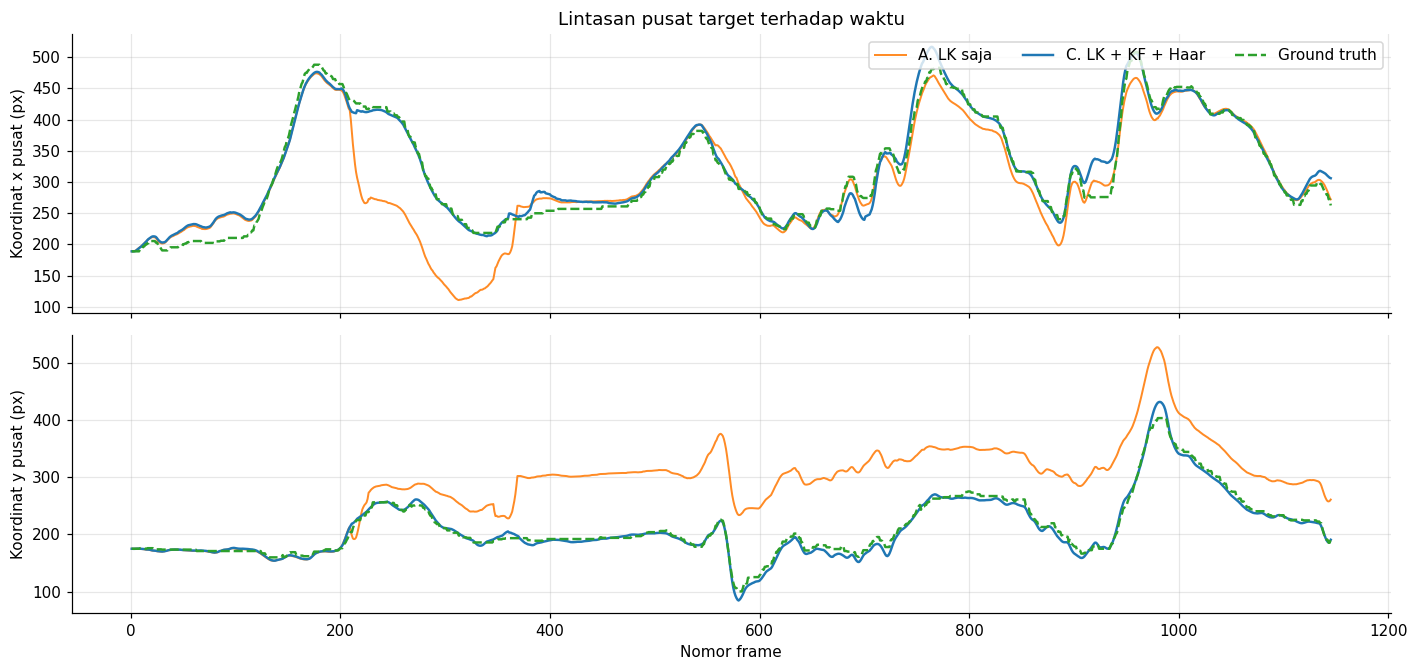

In [15]:
WARNA_PLOT = {"GT": "#2ca02c", "A": "#ff7f0e", "B": "#7f7f7f", "C": "#1f77b4"}
SEGMEN = {
    "Awal sekuens": (1, 203),
    "Oklusi tangan": (204, 230),
    "Tangan di kacamata, kepala miring": (340, 400),
    "Menoleh, kamera bergerak": (680, 770),
    "Wajah ke tepi bingkai": (905, 990),
    "Akhir sekuens": (1135, 1145),
}

fig, axs = plt.subplots(2, 1, figsize=(13, 6.2), sharex=True)
for ax, kol, lab in zip(axs, ["cx", "cy"], ["Koordinat x pusat (px)", "Koordinat y pusat (px)"]):
    ax.plot(DF_A["frame"], DF_A[kol], color=WARNA_PLOT["A"], lw=1.3, alpha=0.9, label="A. LK saja")
    ax.plot(DF_C["frame"], DF_C[kol], color=WARNA_PLOT["C"], lw=1.6, label="C. LK + KF + Haar")
    ax.plot(DF_C["frame"], GT_C[:, 0 if kol == "cx" else 1], color=WARNA_PLOT["GT"], lw=1.6, ls="--", label="Ground truth")
    ax.set_ylabel(lab)
axs[0].legend(ncol=3, loc="upper right")
axs[1].set_xlabel("Nomor frame")
axs[0].set_title("Lintasan pusat target terhadap waktu")
plt.tight_layout()
plt.savefig(OUT_DIR / "fig_lintasan.png", dpi=150, bbox_inches="tight")
plt.show()

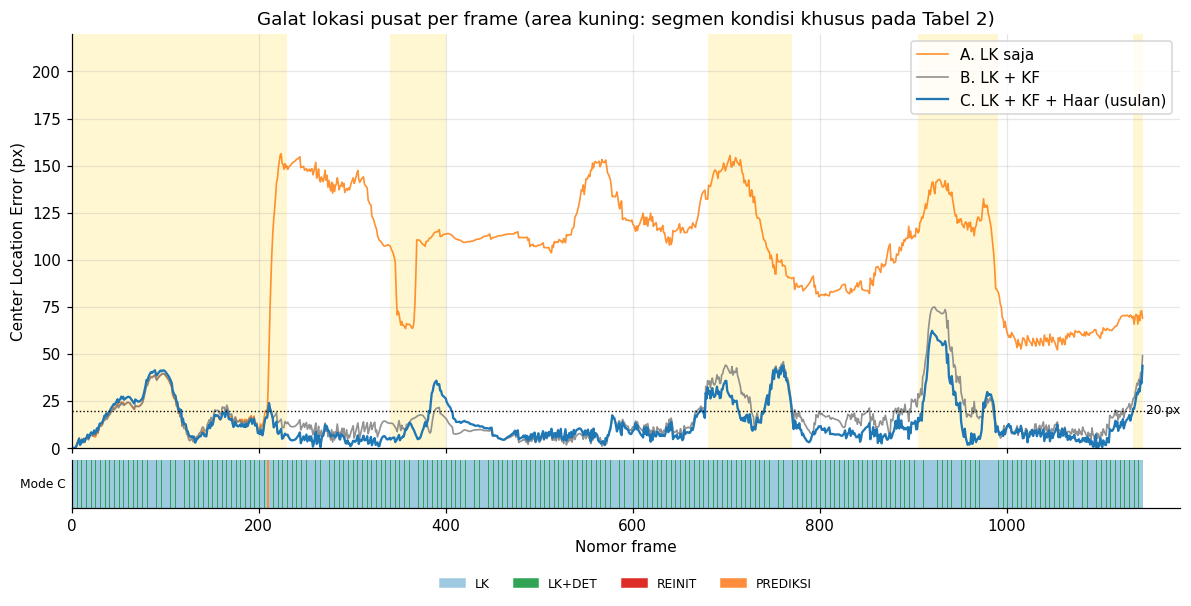

In [16]:
WARNA_MODE = {"INIT": "#bbbbbb", "LK": "#9ecae1", "LK+DET": "#31a354", "DET": "#756bb1",
              "REINIT": "#de2d26", "PREDIKSI": "#fd8d3c", "HILANG": "#636363"}
fig, (ax, axm) = plt.subplots(2, 1, figsize=(13, 5.6), sharex=True, gridspec_kw=dict(height_ratios=[6, 0.7], hspace=0.05))
for k in ["A", "B", "C"]:
    ax.plot(DF_C["frame"], METRIK[k]["cle"], color=WARNA_PLOT[k], lw=1.5 if k == "C" else 1.1,
            alpha=1 if k == "C" else 0.85, label=NAMA[k])
ax.axhline(AMBANG_PRESISI, color="k", ls=":", lw=0.9)
ax.text(N_FRAME + 4, AMBANG_PRESISI, "20 px", va="center", fontsize=8)
for nm, (a, b) in SEGMEN.items():
    ax.axvspan(a, b, color="gold", alpha=0.18, lw=0)
ax.set_ylim(0, 220)
ax.set_ylabel("Center Location Error (px)")
ax.set_title("Galat lokasi pusat per frame (area kuning: segmen kondisi khusus pada Tabel 2)")
ax.legend(loc="upper right")
from matplotlib.colors import to_rgb
pita = np.array([[to_rgb(WARNA_MODE[m]) for m in DF_C["mode"]]])
axm.imshow(pita, aspect="auto", extent=(0.5, N_FRAME + 0.5, 0, 1), interpolation="nearest")
axm.set_xlim(0, N_FRAME + 40)
axm.set_yticks([])
axm.set_xlabel("Nomor frame")
axm.set_ylabel("Mode C", rotation=0, ha="right", va="center", fontsize=8)
axm.grid(False)
handles = [plt.Rectangle((0, 0), 1, 1, color=WARNA_MODE[k]) for k in ["LK", "LK+DET", "REINIT", "PREDIKSI"]]
axm.legend(handles, ["LK", "LK+DET", "REINIT", "PREDIKSI"], ncol=4, loc="upper center",
           bbox_to_anchor=(0.5, -1.2), fontsize=8, frameon=False)
plt.savefig(OUT_DIR / "fig_cle.png", dpi=150, bbox_inches="tight")
plt.show()

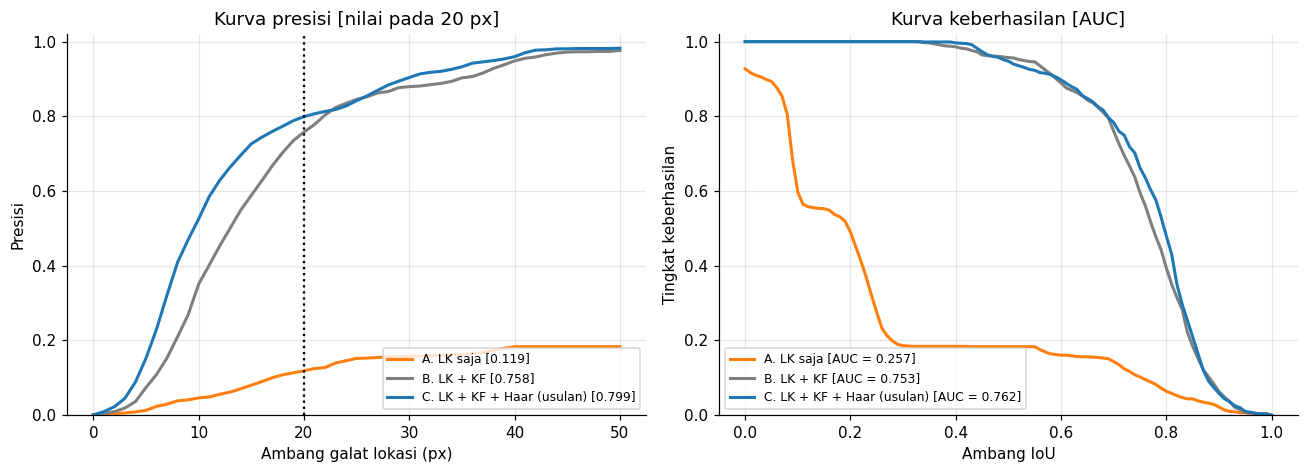

In [17]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.4))
ambang_px = np.arange(0, 51)
for k in ["A", "B", "C"]:
    cle = METRIK[k]["cle"]
    pres = [(cle <= t).mean() for t in ambang_px]
    a1.plot(ambang_px, pres, color=WARNA_PLOT[k], lw=2, label=f"{NAMA[k]} [{METRIK[k]['presisi20']:.3f}]")
    a2.plot(AMBANG_IOU, METRIK[k]["kurva_sukses"], color=WARNA_PLOT[k], lw=2, label=f"{NAMA[k]} [AUC = {METRIK[k]['auc']:.3f}]")
a1.axvline(AMBANG_PRESISI, color="k", ls=":")
a1.set(xlabel="Ambang galat lokasi (px)", ylabel="Presisi", title="Kurva presisi [nilai pada 20 px]", ylim=(0, 1.02))
a2.set(xlabel="Ambang IoU", ylabel="Tingkat keberhasilan", title="Kurva keberhasilan [AUC]", ylim=(0, 1.02))
a1.legend(loc="lower right", fontsize=8)
a2.legend(loc="lower left", fontsize=8)
plt.tight_layout()
plt.savefig(OUT_DIR / "fig_kurva.png", dpi=150, bbox_inches="tight")
plt.show()

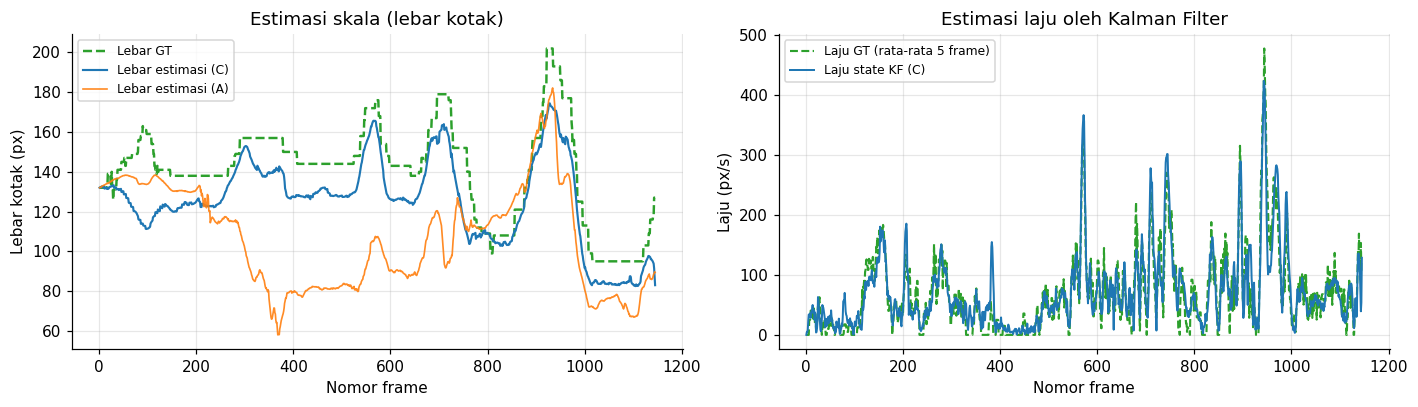

Rasio lebar estimasi/GT (C): median 0.89, persentil 5-95: 0.79-0.99


In [18]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 3.8))
a1.plot(DF_C["frame"], GT[:, 2], color=WARNA_PLOT["GT"], ls="--", lw=1.6, label="Lebar GT")
a1.plot(DF_C["frame"], DF_C["w"], color=WARNA_PLOT["C"], lw=1.4, label="Lebar estimasi (C)")
a1.plot(DF_A["frame"], DF_A["w"], color=WARNA_PLOT["A"], lw=1.1, alpha=0.9, label="Lebar estimasi (A)")
a1.set(xlabel="Nomor frame", ylabel="Lebar kotak (px)", title="Estimasi skala (lebar kotak)")
a1.legend(fontsize=8)
v_gt = np.r_[0, np.hypot(*np.diff(GT_C, axis=0).T)] * FPS
v_gt_halus = np.convolve(v_gt, np.ones(5) / 5, mode="same")
a2.plot(DF_C["frame"], v_gt_halus, color=WARNA_PLOT["GT"], ls="--", lw=1.4, label="Laju GT (rata-rata 5 frame)")
a2.plot(DF_C["frame"], np.hypot(DF_C["vx"], DF_C["vy"]), color=WARNA_PLOT["C"], lw=1.3, label="Laju state KF (C)")
a2.set(xlabel="Nomor frame", ylabel="Laju (px/s)", title="Estimasi laju oleh Kalman Filter")
a2.legend(fontsize=8)
plt.tight_layout()
plt.savefig(OUT_DIR / "fig_ukuran_laju.png", dpi=150, bbox_inches="tight")
plt.show()
print("Rasio lebar estimasi/GT (C): median %.2f, persentil 5-95: %.2f-%.2f" % (
    np.median(DF_C["w"] / GT[:, 2]), *np.percentile(DF_C["w"] / GT[:, 2], [5, 95])))

### 5.2 Kinerja menurut kondisi
Kondisi khusus pada Tabel 2 ditentukan dari pengamatan frame. Setiap segmen berisi satu kondisi dominan: oklusi tangan, tangan menyentuh kacamata dengan kepala miring, kepala menoleh disertai gerak kamera, wajah menuju tepi bingkai, dan akhir sekuens. Tabel di bawah memuat rata-rata CLE per segmen, disusul daftar episode galat besar.

In [19]:
def tabel_segmen(hasil: dict, metrik: dict) -> pd.DataFrame:
    baris = []
    for nm, (a, b) in SEGMEN.items():
        sl = slice(a - 1, b)
        r = {"Segmen kondisi": f"{nm} ({a}-{b})"}
        for k in ["A", "B", "C"]:
            r[f"CLE {k} (px)"] = metrik[k]["cle"][sl].mean()
        r["IoU C"] = metrik["C"]["iou"][sl].mean()
        baris.append(r)
    baris.append({"Segmen kondisi": f"Seluruh sekuens (1-{N_FRAME})",
                  **{f"CLE {k} (px)": metrik[k]["cle"].mean() for k in ["A", "B", "C"]},
                  "IoU C": metrik["C"]["iou"].mean()})
    return pd.DataFrame(baris).set_index("Segmen kondisi").round(1)


TABEL_SEGMEN = tabel_segmen(HASIL, METRIK)
display(TABEL_SEGMEN)


def episode_galat(cle, ambang=30.0, panjang_min=5):
    """Mengelompokkan frame berurutan dengan CLE > ambang menjadi episode kegagalan."""
    ep, s = [], None
    for k, v in enumerate(cle):
        if v > ambang and s is None:
            s = k
        if v <= ambang and s is not None:
            if k - s >= panjang_min:
                ep.append((s + 1, k, k - s, cle[s:k].max(), s + 1 + int(np.argmax(cle[s:k]))))
            s = None
    if s is not None and len(cle) - s >= panjang_min:
        ep.append((s + 1, len(cle), len(cle) - s, cle[s:].max(), s + 1 + int(np.argmax(cle[s:]))))
    return pd.DataFrame(ep, columns=["mulai", "selesai", "panjang (frame)", "CLE maks (px)", "frame puncak"])


print("Episode galat metode C (CLE > 30 px selama >= 5 frame berturut-turut):")
display(episode_galat(METRIK["C"]["cle"]).round(1))
print("Episode galat metode A:")
display(episode_galat(METRIK["A"]["cle"]).round(1))

,CLE A (px),CLE B (px),CLE C (px),IoU C
Segmen kondisi,,,,
Awal sekuens (1-203),17.6,17.7,18.2,0.7
Oklusi tangan (204-230),101.5,15.5,12.1,0.8
"Tangan di kacamata, kepala miring (340-400)",95.3,14.7,14.8,0.7
"Menoleh, kamera bergerak (680-770)",127.0,32.6,26.4,0.6
Wajah ke tepi bingkai (905-990),124.8,39.1,28.0,0.7
Akhir sekuens (1135-1145),69.5,34.6,29.6,0.5
Seluruh sekuens (1-1145),91.3,16.5,13.5,0.8


Episode galat metode C (CLE > 30 px selama >= 5 frame berturut-turut):


,mulai,selesai,panjang (frame),CLE maks (px),frame puncak
0,78,108,31,41.4,89
1,386,395,10,35.8,390
2,695,701,7,35.7,699
3,747,767,21,43.9,761
4,913,942,30,62.3,920
5,1141,1145,5,43.7,1145


Episode galat metode A:


,mulai,selesai,panjang (frame),CLE maks (px),frame puncak
0,79,107,29,39.6,97
1,210,1145,936,156.3,224


### 5.3 Konsistensi filter
Filter yang kovarians noisenya tepat memiliki NIS rata-rata sama dengan derajat bebas pengukuran (2 untuk pengukuran dua dimensi). Nilai yang jauh di bawah 2 berarti filter terlalu pesimistis, sedangkan nilai di atas 2 berarti terlalu optimistis. Uji ini tidak memakai *ground truth*.

In [20]:
def ringkas_nis(df, cfg):
    nl = df["nis_lk"].dropna()
    nd = df["nis_det"].dropna()
    return dict(
        lk_diperiksa=int(len(nl)), lk_ditolak=int((nl > cfg.gerbang_lk).sum()),
        lk_nis_rata=float(nl[nl <= cfg.gerbang_lk].mean()),
        det_diperiksa=int(len(nd)), det_di_luar_gerbang=int((nd > cfg.gerbang_det).sum()),
        det_nis_rata=float(nd[nd <= cfg.gerbang_det].mean()) if len(nd) else np.nan)


NIS_C = ringkas_nis(DF_C, CFG_C)
print("Konsistensi filter (metode C) - nilai harapan NIS rata-rata = derajat bebas = 2")
print(f"  Pengukuran LK       : diperiksa {NIS_C['lk_diperiksa']}, ditolak gerbang {NIS_C['lk_ditolak']}, NIS rata-rata {NIS_C['lk_nis_rata']:.3f}")
print(f"  Pengukuran deteksi  : diperiksa {NIS_C['det_diperiksa']}, di luar gerbang {NIS_C['det_di_luar_gerbang']}, NIS rata-rata {NIS_C['det_nis_rata']:.3f}")
print("Mode per frame (C):")
print(DF_C["mode"].value_counts().to_string())

Konsistensi filter (metode C) - nilai harapan NIS rata-rata = derajat bebas = 2
  Pengukuran LK       : diperiksa 1144, ditolak gerbang 2, NIS rata-rata 0.047
  Pengukuran deteksi  : diperiksa 220, di luar gerbang 1, NIS rata-rata 0.170
Mode per frame (C):
mode
LK          923
LK+DET      219
PREDIKSI      2
INIT          1


## 6. Studi ablasi dan sensitivitas
Bagian ini menjawab tiga pertanyaan: komponen mana yang menyumbang pada kinerja, apa peran aliran optik bila detektor tersedia, dan seberapa kokoh hasilnya terhadap parameter.

### 6.1 Ablasi komponen
* **C′** menyegarkan titik fitur setiap kali deteksi diterima. Varian ini ditambahkan setelah pengamatan awal menunjukkan titik fitur terjebak pada tangan saat oklusi, sehingga ia mendokumentasikan alasan kebijakan penyegaran di metode C.
* **C−** menonaktifkan re-inisialisasi pada gerbang detektor.
* **E** dan **D** menghilangkan aliran optik: Kalman Filter hanya menerima posisi dari detektor, tiap lima frame (E) atau tiap frame (D).

In [21]:
def jalankan_varian(nama, cfg):
    df, _, nd = jalankan_tracker(cfg)
    m = evaluasi(df)
    nis = df["nis_lk"].dropna()
    return {"Varian": nama, "RMSE (px)": m["rmse"], "Presisi@20px": m["presisi20"], "AUC sukses": m["auc"],
            "Sukses@IoU>0,5": m["sukses50"], "Panggilan detektor": nd,
            "NIS LK rata-rata": float(nis[nis <= cfg.gerbang_lk].mean()) if len(nis) else np.nan,
            "Ditolak gerbang LK": int((nis > cfg.gerbang_lk).sum())}


t0 = time.time()
VARIAN = [
    ("A. LK saja", CFG_A),
    ("B. LK + KF (tanpa detektor)", CFG_B),
    ("C. LK + KF + Haar (usulan)", CFG_C),
    ("C'. seed ulang titik di setiap deteksi", replace(CFG_C, seed_saat_deteksi=True)),
    ("C-. tanpa re-inisialisasi", replace(CFG_C, gamma_reinit=0.0)),
    ("E. KF + Haar tiap 5 frame (tanpa LK)", replace(CFG_C, pakai_lk=False, interval_deteksi=5)),
    ("D. KF + Haar tiap frame (tanpa LK)", replace(CFG_C, pakai_lk=False, interval_deteksi=1)),
]
TABEL_ABLASI = pd.DataFrame([jalankan_varian(n, c) for n, c in VARIAN]).set_index("Varian")
print(f"Ablasi komponen selesai dalam {time.time() - t0:.1f} detik")
display(TABEL_ABLASI.drop(columns=["NIS LK rata-rata", "Ditolak gerbang LK"]).round(3))

Ablasi komponen selesai dalam 23.1 detik


,RMSE (px),Presisi@20px,AUC sukses,"Sukses@IoU>0,5",Panggilan detektor
Varian,,,,,
A. LK saja,101.199,0.119,0.257,0.183,0
B. LK + KF (tanpa detektor),20.714,0.758,0.753,0.957,0
C. LK + KF + Haar (usulan),17.577,0.799,0.762,0.948,229
C'. seed ulang titik di setiap deteksi,54.636,0.679,0.663,0.832,231
C-. tanpa re-inisialisasi,17.577,0.799,0.762,0.948,229
E. KF + Haar tiap 5 frame (tanpa LK),17.395,0.800,0.762,0.951,228
D. KF + Haar tiap frame (tanpa LK),17.015,0.796,0.765,0.948,1144


### 6.2 Peran aliran optik di antara dua deteksi
Interval deteksi divariasikan dari 1 sampai 100 frame. Untuk tiap interval, varian dengan aliran optik (LK + KF + Haar) dibandingkan dengan varian tanpa aliran optik (KF + Haar, prediksi *Constant Velocity* di antara deteksi). Jumlah panggilan detektor dipakai sebagai ukuran biaya komputasi.

Sapuan interval selesai dalam 31.5 detik


,Panggilan detektor,RMSE dengan LK (px),RMSE tanpa LK (px),Presisi@20 dengan LK,Presisi@20 tanpa LK,AUC dengan LK,AUC tanpa LK
Interval deteksi (frame),,,,,,,
1,1144,16.989,17.015,0.804,0.796,0.764,0.765
2,573,17.115,16.623,0.805,0.805,0.766,0.768
5,229,17.577,17.395,0.799,0.800,0.762,0.762
10,116,17.917,35.217,0.796,0.700,0.757,0.719
25,47,18.026,49.934,0.796,0.502,0.758,0.612
50,24,19.094,70.293,0.780,0.317,0.755,0.481
100,13,19.364,114.089,0.781,0.253,0.763,0.406


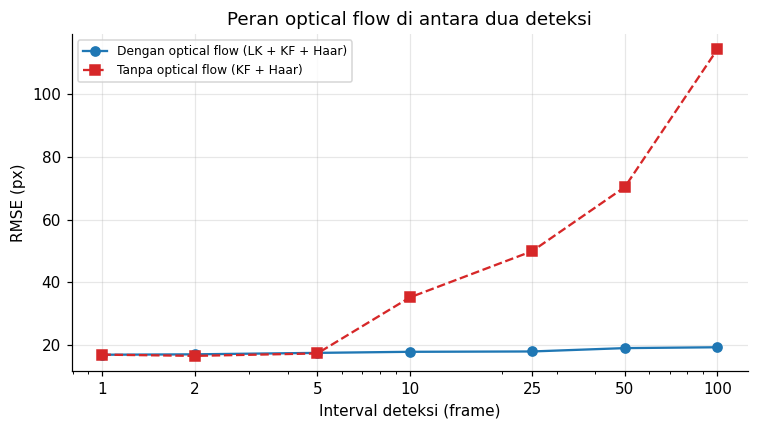

In [22]:
t0 = time.time()
INTERVAL = [1, 2, 5, 10, 25, 50, 100]
baris = []
for k in INTERVAL:
    r1 = jalankan_varian("LK+KF+Haar", replace(CFG_C, interval_deteksi=k))
    r2 = jalankan_varian("KF+Haar", replace(CFG_C, pakai_lk=False, interval_deteksi=k))
    baris.append({"Interval deteksi (frame)": k, "Panggilan detektor": r1["Panggilan detektor"],
                  "RMSE dengan LK (px)": r1["RMSE (px)"], "RMSE tanpa LK (px)": r2["RMSE (px)"],
                  "Presisi@20 dengan LK": r1["Presisi@20px"], "Presisi@20 tanpa LK": r2["Presisi@20px"],
                  "AUC dengan LK": r1["AUC sukses"], "AUC tanpa LK": r2["AUC sukses"]})
TABEL_INTERVAL = pd.DataFrame(baris).set_index("Interval deteksi (frame)")
print(f"Sapuan interval selesai dalam {time.time() - t0:.1f} detik")
display(TABEL_INTERVAL.round(3))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(INTERVAL, TABEL_INTERVAL["RMSE dengan LK (px)"], "o-", color=WARNA_PLOT["C"], label="Dengan optical flow (LK + KF + Haar)")
ax.plot(INTERVAL, TABEL_INTERVAL["RMSE tanpa LK (px)"], "s--", color="#d62728", label="Tanpa optical flow (KF + Haar)")
ax.set_xscale("log")
ax.set_xticks(INTERVAL)
ax.set_xticklabels(INTERVAL)
ax.set(xlabel="Interval deteksi (frame)", ylabel="RMSE (px)", title="Peran optical flow di antara dua deteksi")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(OUT_DIR / "fig_interval.png", dpi=150, bbox_inches="tight")
plt.show()

### 6.3 Kepekaan terhadap $\sigma_a$ dan $\sigma_v$
Setiap kombinasi $\sigma_a\in\{300,1000,2500,5000\}$ px/s² dan $\sigma_v\in\{15,30,60\}$ px/s dijalankan untuk varian B, C, dan C−. Kolom NIS merangkum konsistensi filter pada setiap $\sigma_a$.

In [23]:
t0 = time.time()
baris = []
for sa in [300, 1000, 2500, 5000]:
    for sv in [15, 30, 60]:
        for nm, dasar in [("B", CFG_B), ("C", CFG_C), ("C-", replace(CFG_C, gamma_reinit=0.0))]:
            r = jalankan_varian(nm, replace(dasar, sigma_a=sa, sigma_v=sv))
            baris.append({"sigma_a": sa, "sigma_v": sv, "Varian": nm, "RMSE": r["RMSE (px)"],
                          "NIS LK": r["NIS LK rata-rata"], "Ditolak LK": r["Ditolak gerbang LK"]})
SENS = pd.DataFrame(baris)
print(f"Analisis sensitivitas selesai dalam {time.time() - t0:.1f} detik")
RMSE_GRID = SENS.pivot_table(index=["sigma_a", "sigma_v"], columns="Varian", values="RMSE").round(1)
display(RMSE_GRID[["B", "C", "C-"]])
NIS_GRID = SENS[SENS["Varian"] == "C"].groupby("sigma_a").agg(NIS_LK=("NIS LK", "mean"), Ditolak_LK=("Ditolak LK", "mean")).round(2)
print("Konsistensi NIS terhadap sigma_a (rata-rata atas sigma_v, metode C):")
display(NIS_GRID)

Analisis sensitivitas selesai dalam 160.8 detik


Varian               B     C     C-
sigma_a sigma_v                    
300     15       240.7  18.3  210.1
        30       190.5  15.9   15.9
        60        58.5  16.6   16.6
1000    15        19.0  17.6   17.6
        30        18.6  17.6   17.6
        60        19.3  16.9   16.9
2500    15        18.8  17.5   17.5
        30        20.7  17.6   17.6
        60        21.0  17.6   44.7
5000    15        74.9  18.6   48.5
        30        74.9  18.2   48.7
        60        75.9  17.6   45.5

Konsistensi NIS terhadap sigma_a (rata-rata atas sigma_v, metode C):


,NIS_LK,Ditolak_LK
sigma_a,,
300,0.95,73.33
1000,0.23,2.00
2500,0.05,2.00
5000,0.02,0.00


## 7. Video hasil pelacakan
Video memuat satu panel dengan lapisan berikut: kotak *ground truth* (hijau), estimasi metode C (biru), kotak metode A atau LK saja (oranye), titik fitur dan vektor aliran optik (kuning), jejak 40 frame terakhir (magenta), serta lingkaran ketidakpastian posisi 2σ dari Kalman Filter (putih). Header video menampilkan nomor frame, mode, jumlah titik LK aktif, CLE, dan IoU. Video disimpan dengan codec H.264 (`yuv420p`, *faststart*) agar dapat diputar langsung di peramban dan Google Drive.

In [24]:
SKALA = 1.5
H_HEADER, H_FOOTER = 56, 44
W_OUT = int(round(LEBAR * SKALA))
H_IMG = int(round(TINGGI * SKALA))
H_OUT = H_IMG + H_HEADER + H_FOOTER
assert W_OUT % 2 == 0 and H_OUT % 2 == 0, "Dimensi video harus genap untuk H.264 yuv420p."
BGR = dict(gt=(60, 230, 60), c=(255, 190, 0), a=(0, 128, 255), lk=(0, 255, 255),
           jejak=(255, 0, 255), sigma=(255, 255, 255), teks=(255, 255, 255))
WARNA_TEKS_MODE = {"INIT": (200, 200, 200), "LK": (255, 255, 255), "LK+DET": (90, 230, 90),
                   "DET": (230, 150, 180), "REINIT": (80, 80, 255), "PREDIKSI": (0, 165, 255)}


def _s(v):
    return int(round(float(v) * SKALA))


def _kotak(img, x, y, w, h, warna, tebal):
    cv2.rectangle(img, (_s(x), _s(y)), (_s(x + w), _s(y + h)), warna, tebal, cv2.LINE_AA)


def gambar_citra(i, df_c, titik_c, df_a, jejak=40, tampil_a=True):
    """Citra frame ke-i (indeks 0) dengan seluruh lapisan visualisasi, tanpa header/footer."""
    img = cv2.cvtColor(cv2.resize(FRAMES[i], (W_OUT, H_IMG), interpolation=cv2.INTER_CUBIC), cv2.COLOR_GRAY2BGR)
    for a in range(max(1, i - jejak + 1), i + 1):                       # jejak lintasan estimasi C
        p, q = df_c.iloc[a - 1], df_c.iloc[a]
        cv2.line(img, (_s(p.cx), _s(p.cy)), (_s(q.cx), _s(q.cy)), BGR["jejak"], 2, cv2.LINE_AA)
    old, new = titik_c[i]
    for p0, p1 in zip(old, new):                                        # titik fitur dan vektor aliran optik
        cv2.line(img, (_s(p0[0]), _s(p0[1])), (_s(p1[0]), _s(p1[1])), BGR["lk"], 1, cv2.LINE_AA)
        cv2.circle(img, (_s(p1[0]), _s(p1[1])), 2, BGR["lk"], -1, cv2.LINE_AA)
    _kotak(img, *GT[i], BGR["gt"], 2)                                   # ground truth
    if tampil_a:
        a_ = df_a.iloc[i]
        _kotak(img, a_.x, a_.y, a_.w, a_.h, BGR["a"], 2)
    c_ = df_c.iloc[i]
    _kotak(img, c_.x, c_.y, c_.w, c_.h, BGR["c"], 3)
    cv2.circle(img, (_s(c_.cx), _s(c_.cy)), 4, BGR["c"], -1, cv2.LINE_AA)
    if np.isfinite(c_.sigma_pos):                                       # lingkaran ketidakpastian 2-sigma
        cv2.circle(img, (_s(c_.cx), _s(c_.cy)), max(2, _s(2 * c_.sigma_pos)), BGR["sigma"], 1, cv2.LINE_AA)
    return img


def buat_frame(i, df_c, titik_c, df_a):
    """Kanvas video lengkap: header (status), citra beranotasi, dan footer (legenda)."""
    kanvas = np.full((H_OUT, W_OUT, 3), 28, np.uint8)
    kanvas[H_HEADER:H_HEADER + H_IMG] = gambar_citra(i, df_c, titik_c, df_a)
    c_ = df_c.iloc[i]
    cle_c, cle_a, iou_c = METRIK["C"]["cle"][i], METRIK["A"]["cle"][i], METRIK["C"]["iou"][i]
    f = cv2.FONT_HERSHEY_SIMPLEX
    judul = f"Dudek (OTB-100)  |  Frame {i + 1:04d}/{N_FRAME}  |  t = {i * DT:5.2f} s  |  Mode C:"
    cv2.putText(kanvas, judul, (14, 22), f, 0.62, BGR["teks"], 1, cv2.LINE_AA)
    x_mode = 14 + cv2.getTextSize(judul, f, 0.62, 1)[0][0] + 10
    cv2.putText(kanvas, c_["mode"], (x_mode, 22), f, 0.62, WARNA_TEKS_MODE.get(c_["mode"], BGR["teks"]), 2, cv2.LINE_AA)
    cv2.putText(kanvas, f"Titik LK aktif: {int(c_.n_lk):3d}  |  CLE (C): {cle_c:6.1f} px  |  IoU (C): {iou_c:4.2f}  |  CLE (A): {cle_a:6.1f} px",
                (14, 46), f, 0.62, BGR["teks"], 1, cv2.LINE_AA)
    item = [("Ground truth", BGR["gt"]), ("Estimasi C (LK+KF+Haar)", BGR["c"]), ("LK saja (A)", BGR["a"]),
            ("Titik/vektor LK", BGR["lk"]), ("Jejak 40 frame", BGR["jejak"]), ("2-sigma KF", BGR["sigma"])]
    x = 14
    for nama, w in item:
        cv2.rectangle(kanvas, (x, H_OUT - 29), (x + 16, H_OUT - 13), w, -1)
        cv2.putText(kanvas, nama, (x + 22, H_OUT - 15), f, 0.5, BGR["teks"], 1, cv2.LINE_AA)
        x += 22 + int(cv2.getTextSize(nama, f, 0.5, 1)[0][0]) + 22
    return kanvas


def tulis_video(path, df_c, titik_c, df_a, crf=21):
    """Menulis video H.264 (yuv420p, faststart) agar dapat diputar di peramban dan Google Drive."""
    path = Path(path)
    if shutil.which("ffmpeg"):
        cmd = ["ffmpeg", "-y", "-loglevel", "error", "-f", "rawvideo", "-pix_fmt", "bgr24",
               "-s", f"{W_OUT}x{H_OUT}", "-r", f"{FPS}", "-i", "-", "-c:v", "libx264",
               "-preset", "veryfast", "-crf", str(crf), "-pix_fmt", "yuv420p", "-movflags", "+faststart", str(path)]
        proses = subprocess.Popen(cmd, stdin=subprocess.PIPE)
        for i in range(N_FRAME):
            proses.stdin.write(buat_frame(i, df_c, titik_c, df_a).tobytes())
        proses.stdin.close()
        assert proses.wait() == 0, "ffmpeg gagal menulis video."
    else:
        print("[PERINGATAN] ffmpeg tidak ditemukan; memakai codec mp4v (kompatibilitas pemutar lebih rendah).")
        vw = cv2.VideoWriter(str(path), cv2.VideoWriter_fourcc(*"mp4v"), FPS, (W_OUT, H_OUT))
        for i in range(N_FRAME):
            vw.write(buat_frame(i, df_c, titik_c, df_a))
        vw.release()

### 7.1 Cuplikan hasil
Delapan frame berikut dipilih untuk menunjukkan kondisi awal, kepala menoleh (89), oklusi tangan (212), kegagalan metode A (300 dan 520), gerak kamera (761), wajah di tepi bingkai (979), dan akhir sekuens (1145).

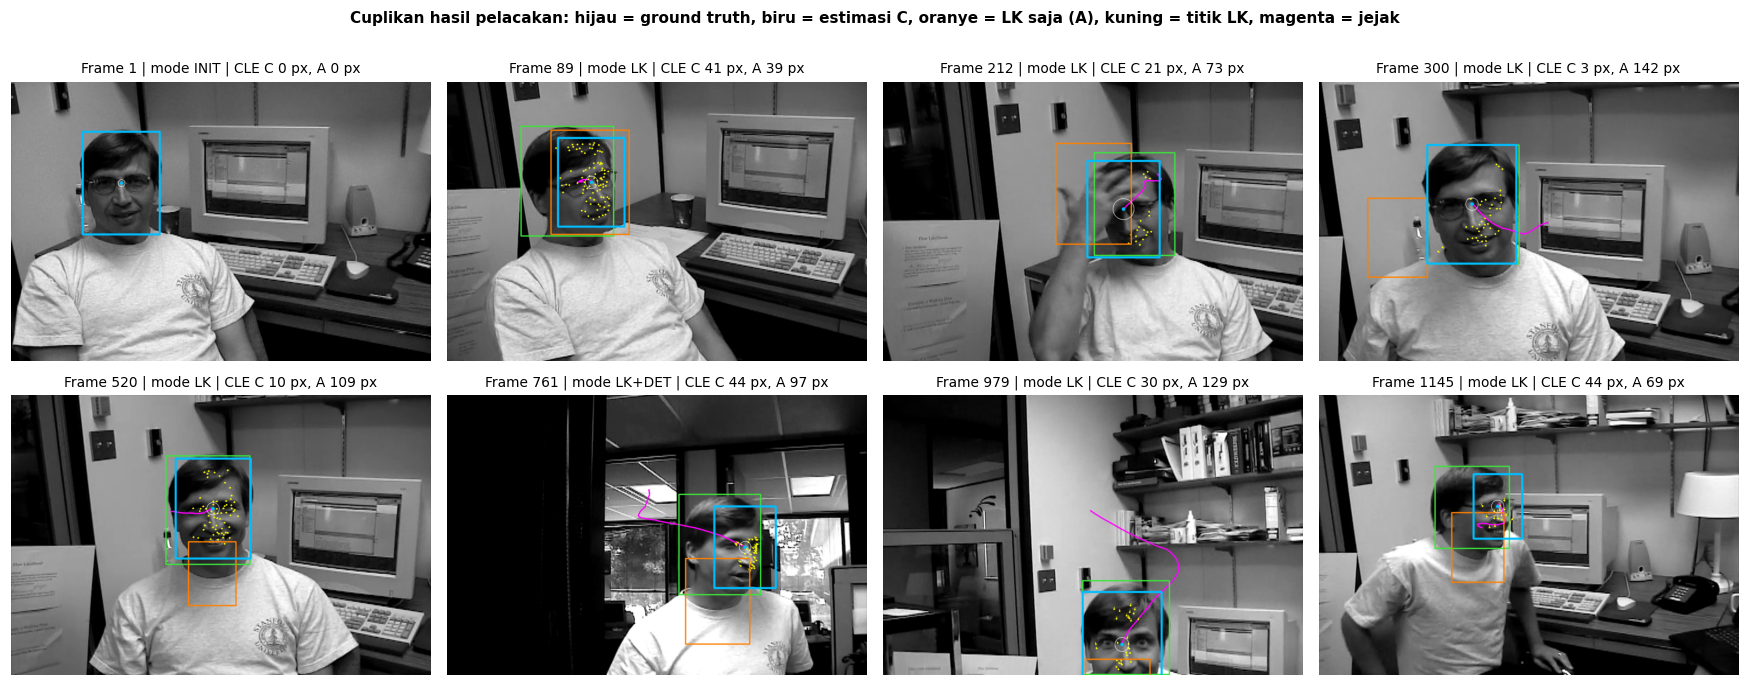

In [25]:
SNAP = [1, 89, 212, 300, 520, 761, 979, 1145]
fig, axs = plt.subplots(2, 4, figsize=(16, 6.4))
for ax, f in zip(axs.ravel(), SNAP):
    img = gambar_citra(f - 1, DF_C, TITIK_C, DF_A)
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.set_title(f"Frame {f} | mode {DF_C.loc[f - 1, 'mode']} | CLE C {METRIK['C']['cle'][f - 1]:.0f} px, A {METRIK['A']['cle'][f - 1]:.0f} px",
                 fontsize=9)
    ax.axis("off")
plt.suptitle("Cuplikan hasil pelacakan: hijau = ground truth, biru = estimasi C, oranye = LK saja (A), kuning = titik LK, magenta = jejak",
             y=1.0, fontsize=10, fontweight="bold")
plt.tight_layout()
plt.savefig(OUT_DIR / "fig_snapshot.png", dpi=140, bbox_inches="tight")
plt.show()

In [26]:
t0 = time.time()
PATH_MP4 = OUT_DIR / "hasil_tracking_dudek.mp4"
tulis_video(PATH_MP4, DF_C, TITIK_C, DF_A)
print(f"Video ditulis dalam {time.time() - t0:.1f} detik -> {PATH_MP4} ({PATH_MP4.stat().st_size / 1e6:.1f} MB)")

cek = cv2.VideoCapture(str(PATH_MP4))
n_cek = 0
while cek.read()[0]:
    n_cek += 1
fps_cek, w_cek, h_cek = cek.get(cv2.CAP_PROP_FPS), int(cek.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cek.get(cv2.CAP_PROP_FRAME_HEIGHT))
cek.release()
print(f"Verifikasi video: {n_cek} frame, {w_cek}x{h_cek}, {fps_cek:.1f} FPS, durasi {n_cek / fps_cek:.1f} detik")
assert n_cek == N_FRAME, "Jumlah frame video tidak sama dengan jumlah frame sekuens."
if shutil.which("ffprobe"):
    kodek = subprocess.run(["ffprobe", "-v", "error", "-select_streams", "v:0", "-show_entries", "stream=codec_name,pix_fmt",
                            "-of", "csv=p=0", str(PATH_MP4)], capture_output=True, text=True).stdout.strip()
    print("Kodek / format piksel:", kodek)

Video ditulis dalam 37.3 detik -> /content/keluaran_tracking/hasil_tracking_dudek.mp4 (15.3 MB)
Verifikasi video: 1145 frame, 1080x820, 25.0 FPS, durasi 45.8 detik
Kodek / format piksel: h264,yuv420p


## 8. Ekspor luaran
Sel terakhir menyimpan tabel lintasan lengkap (`.csv`), ringkasan metrik dan konfigurasi (`.json`), serta gambar yang dipakai pada laporan. Seluruh berkas berada di direktori `keluaran_tracking`. Pada Colab, unduh isi direktori ini, lalu unggah ke Google Drive bersama notebook.

In [27]:
GT_DF = pd.DataFrame({"gt_x": GT[:, 0], "gt_y": GT[:, 1], "gt_w": GT[:, 2], "gt_h": GT[:, 3],
                      "gt_cx": GT_C[:, 0], "gt_cy": GT_C[:, 1]})
EKSPOR = pd.concat([DF_C.rename(columns={"x": "est_x", "y": "est_y", "w": "est_w", "h": "est_h", "cx": "est_cx", "cy": "est_cy",
                                         "vx": "est_vx_px_s", "vy": "est_vy_px_s", "n_lk": "titik_lk_aktif"}), GT_DF], axis=1)
EKSPOR["cle_C_px"] = METRIK["C"]["cle"]
EKSPOR["iou_C"] = METRIK["C"]["iou"]
EKSPOR["cle_A_px"] = METRIK["A"]["cle"]
EKSPOR["cle_B_px"] = METRIK["B"]["cle"]
PATH_CSV = OUT_DIR / "trajektori_hasil_tracking.csv"
EKSPOR.round(4).to_csv(PATH_CSV, index=False)

RINGKASAN = dict(
    sekuens="OTB-100 Dudek", n_frame=int(N_FRAME), fps=FPS, resolusi=[int(LEBAR), int(TINGGI)],
    versi=dict(python=sys.version.split()[0], opencv=cv2.__version__, numpy=np.__version__, pandas=pd.__version__),
    konfigurasi_C=asdict(CFG_C),
    metrik={k: {n: float(v) for n, v in m.items() if n not in ("cle", "iou", "kurva_sukses")} for k, m in METRIK.items()},
    panggilan_detektor_C=int(N_DET_C), nis_C=NIS_C,
    ablasi=TABEL_ABLASI.round(4).reset_index().to_dict(orient="records"),
    interval=TABEL_INTERVAL.round(4).reset_index().to_dict(orient="records"),
    sensitivitas=SENS.round(4).to_dict(orient="records"),
    segmen=TABEL_SEGMEN.reset_index().to_dict(orient="records"),
    episode_C=episode_galat(METRIK["C"]["cle"]).round(1).to_dict(orient="records"),
    mode_C=DF_C["mode"].value_counts().to_dict(),
    kalibrasi_detektor=dict(offset=OFFSET.tolist(), rasio=RASIO.tolist()))
def bersih(obj):
    """Mengubah NaN menjadi None dan tipe NumPy menjadi tipe Python agar JSON valid."""
    if isinstance(obj, dict):
        return {str(k): bersih(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [bersih(v) for v in obj]
    if isinstance(obj, (np.integer,)):
        return int(obj)
    if isinstance(obj, (float, np.floating)):
        return None if not np.isfinite(obj) else float(obj)
    return obj


PATH_JSON = OUT_DIR / "ringkasan_metrik.json"
with open(PATH_JSON, "w", encoding="utf-8") as f:
    json.dump(bersih(RINGKASAN), f, indent=2, ensure_ascii=False, allow_nan=False)

print("Berkas keluaran:")
for p in sorted(OUT_DIR.iterdir()):
    print(f"  {p.name:36s} {p.stat().st_size / 1e6:8.2f} MB")
display(EKSPOR[["frame", "mode", "est_cx", "est_cy", "gt_cx", "gt_cy", "titik_lk_aktif", "cle_C_px", "iou_C"]].head(8).round(2))

Berkas keluaran:
  fig_cle.png                              0.16 MB
  fig_interval.png                         0.05 MB
  fig_kurva.png                            0.12 MB
  fig_lintasan.png                         0.21 MB
  fig_sampel_dataset.png                   1.08 MB
  fig_snapshot.png                         1.17 MB
  fig_ukuran_laju.png                      0.21 MB
  hasil_tracking_dudek.mp4                15.29 MB
  ringkasan_metrik.json                    0.01 MB
  trajektori_hasil_tracking.csv            0.21 MB


,frame,mode,est_cx,est_cy,gt_cx,gt_cy,titik_lk_aktif,cle_C_px,iou_C
0,1,INIT,189.00,175.00,189.0,175.0,0,0.00,1.00
1,2,LK,188.96,174.87,189.0,175.0,98,0.13,1.00
2,3,LK,189.05,174.81,189.0,175.0,97,0.20,1.00
3,4,LK,189.33,174.85,189.0,175.0,97,0.37,0.99
4,5,LK,190.04,174.96,189.0,175.0,97,1.04,0.98
5,6,LK+DET,191.42,175.15,189.0,175.0,96,2.43,0.96
6,7,LK,192.76,175.16,189.0,175.0,96,3.76,0.94
7,8,LK,194.06,175.15,189.0,175.0,96,5.07,0.92


## 9. Analisis dan kesimpulan
Angka di bawah mengacu pada eksekusi dengan OpenCV 4.11 dan NumPy 2.5. Versi OpenCV lain dapat menghasilkan angka yang sedikit berbeda, terutama karena keluaran detektor Haar dan RANSAC, tetapi pola yang dibahas tetap sama.

### 9.1 Temuan utama
1. **Aliran optik saja tidak cukup (A).** Pelacak A bekerja baik di awal (CLE rata-rata 17,6 px pada frame 1–203), tetapi gagal total ketika tangan menutupi wajah sekitar frame 210. Kotak A tertarik ke arah tangan (cuplikan frame 212), galat melonjak sampai sekitar 150 px, dan pelacak tidak pernah pulih (RMSE 101,2 px; presisi@20 px hanya 11,9%; AUC 0,257). Tidak ada sumber informasi absolut yang dapat menarik estimasi kembali ke wajah.
2. **Kalman Filter dengan gerbang membantu, tetapi hasilnya rapuh tanpa detektor (B).** Pada parameter bawaan, B bertahan melewati oklusi (RMSE 20,7 px; AUC 0,753). Namun pada $\sigma_a=5000$ B gagal (RMSE sekitar 75 px), dan pada $\sigma_a=300$ B gagal pada ketiga nilai $\sigma_v$ (RMSE 58–241 px). Keberhasilan B pada parameter bawaan tidak dapat dianggap kokoh.
3. **Detektor sebagai sensor posisi absolut menstabilkan hasil (C).** Metode C memberi RMSE 17,6 px, presisi@20 px 79,9%, AUC 0,762, dan keberhasilan IoU>0,5 sebesar 94,8%. Pada segmen sulit (kepala menoleh dengan gerak kamera, wajah ke tepi bingkai, akhir sekuens) CLE rata-rata C selalu lebih rendah daripada B. Pada seluruh 12 kombinasi $\sigma_a,\sigma_v$ yang diuji, RMSE C berada pada 15,9–18,6 px.
4. **Re-inisialisasi diperlukan untuk ketahanan, bukan untuk skor pada parameter bawaan.** Pada parameter bawaan C− sama dengan C. Pada lima dari 12 kombinasi parameter, C− memburuk menjadi RMSE sekitar 45–210 px, sedangkan C pada kombinasi yang sama tetap pada 17,6–18,6 px.
5. **Penyegaran titik di setiap deteksi merugikan (C′).** Penjelasan yang paling sesuai dengan pengamatan adalah penyegaran terjadi pada frame 205, ketika tangan mulai menutupi wajah, sehingga titik baru sebagian berada pada tangan. RMSE naik dari 17,6 menjadi 54,6 px. Penyegaran hanya saat titik menipis atau setelah re-inisialisasi menghindari hal ini.
6. **Aliran optik berguna ketika deteksi jarang.** Pada interval 1–5 frame, KF + Haar tanpa LK setara dengan C (RMSE 16,6–17,4 px sebagaimana C 17,0–17,6 px), sehingga pada kasus ini aliran optik tidak menambah akurasi. Pada interval 10 sampai 100 frame, RMSE tanpa LK naik dari 35,2 sampai 114,1 px, sedangkan dengan LK tetap 17,9–19,4 px. Dengan LK, 13 panggilan detektor (interval 100) sudah memberi akurasi mendekati 1144 panggilan.

### 9.2 Kondisi ketika metode gagal atau melemah
* **Kepala menoleh (frame 78–108).** Galat A, B, dan C sama-sama 30–40 px. Karena ketiganya mengalami hal yang sama, penyebabnya bukan detektor. Pada frame 89, kotak anotasi meliputi seluruh kepala termasuk rambut, sedangkan titik fitur terpusat pada bagian wajah, sehingga pusat keduanya berselisih.
* **Wajah mendekat dan miring (frame 913–942).** CLE puncak C 62,3 px dan B 75 px. Estimasi lebar kotak C cenderung lebih kecil daripada anotasi (median rasio 0,89; persentil 5–95: 0,79–0,99), kemungkinan besar karena rasio ukuran deteksi dikalibrasi hanya dari frame 1 (rasio GT/deteksi pada lebar 0,89).
* **Akhir sekuens (frame 1141–1145).** Kepala menoleh dan galat C mencapai 44 px pada frame terakhir.
* **Wajah di tepi bingkai (frame 971–985).** Wajah terpotong bingkai, tetapi kotak C tetap berada pada wajah (cuplikan frame 979: CLE 30 px). CLE rata-rata segmen 905–990 adalah 28,0 px, sebagian besar berasal dari frame 913–942 di atas.
* **Keterbatasan detektor.** Detektor Haar frontal dirancang untuk wajah yang menghadap kamera dan mengeluarkan setidaknya satu kotak pada 95,4% frame; keluarannya tidak diverifikasi satu per satu terhadap anotasi. Pada sekuens dengan beberapa wajah, asosiasi cukup memakai jarak Mahalanobis dan gerbang geometris, tidak memakai pencocokan global seperti algoritma Hungarian.

### 9.3 Konsistensi filter dan keterbatasan model
NIS rata-rata pengukuran LK yang diterima hanya 0,05 (ideal 2), dan hanya 2 dari 1144 pengukuran ditolak gerbang. Artinya filter pada konfigurasi bawaan konservatif: kovarians noise proses cukup besar sehingga estimasi mengikuti pengukuran aliran optik dengan sedikit penghalusan. Menurunkan $\sigma_a$ ke 300 px/s² menaikkan NIS rata-rata hingga mendekati 1, tetapi gerbang lalu menolak rata-rata 73 pengukuran dan varian B kehilangan target. Penyebabnya adalah gerak kepala yang tidak stasioner: periode tenang bergantian dengan gerakan cepat, sedangkan model *Constant Velocity* dengan satu nilai $\sigma_a$ tidak menangkap kedua rezim sekaligus. Perluasan yang wajar adalah model *Constant Acceleration* atau penyesuaian $\sigma_a$ secara adaptif, misalnya dengan *Interacting Multiple Model*.

### 9.4 Keterbatasan percobaan
* Evaluasi hanya memakai **satu sekuens**. Hiperparameter ditetapkan sebelum evaluasi akhir, tetapi kebijakan penyegaran titik dipilih setelah mengamati kegagalan pada sekuens ini (C′), sehingga generalisasi ke sekuens lain belum teruji.
* Kalibrasi detektor memakai kotak awal dari anotasi, sesuai protokol OTB. Pada penerapan nyata, kotak awal harus berasal dari detektor atau masukan pengguna.
* Pelacak tidak melakukan pencarian ulang global setelah wajah hilang lama; pemulihan hanya terjadi bila detektor menemukan wajah dalam radius gerbang.

### 9.5 Kesimpulan
Fusi aliran optik, Kalman Filter, dan detektor menghasilkan pelacak yang jauh lebih kokoh daripada aliran optik saja pada sekuens Dudek: RMSE turun dari 101,2 menjadi 17,6 px, presisi@20 px naik dari 11,9% menjadi 79,9%, dan AUC keberhasilan naik dari 0,257 menjadi 0,762. Kontribusi utama berasal dari pemisahan peran sensor, yaitu aliran optik sebagai sensor kecepatan relatif dan detektor sebagai sensor posisi absolut, ditambah gerbang validasi dan re-inisialisasi. Aliran optik paling bermanfaat ketika detektor dijalankan jarang. Detektor yang dijalankan tiap frame sudah setara, tetapi dengan biaya komputasi lebih besar. Kegagalan yang tersisa berasal dari rotasi kepala dan perbedaan konvensi kotak, yang tidak dapat diperbaiki oleh pemodelan gerak saja.

## Referensi
1. Kalman, R. E. (1960). A new approach to linear filtering and prediction problems. *Journal of Basic Engineering*, 82(1), 35–45.
2. Lucas, B. D., & Kanade, T. (1981). An iterative image registration technique with an application to stereo vision. *Proceedings of IJCAI*, 674–679.
3. Shi, J., & Tomasi, C. (1994). Good features to track. *Proceedings of IEEE CVPR*, 593–600.
4. Bouguet, J.-Y. (2001). *Pyramidal implementation of the Lucas–Kanade feature tracker: Description of the algorithm*. Intel Corporation.
5. Kalal, Z., Mikolajczyk, K., & Matas, J. (2010). Forward-backward error: Automatic detection of tracking failures. *Proceedings of ICPR*, 2756–2759.
6. Viola, P., & Jones, M. (2001). Rapid object detection using a boosted cascade of simple features. *Proceedings of IEEE CVPR*, I-511–I-518.
7. Wu, Y., Lim, J., & Yang, M.-H. (2013). Online object tracking: A benchmark. *Proceedings of IEEE CVPR*, 2411–2418.
8. Bewley, A., Ge, Z., Ott, L., Ramos, F., & Upcroft, B. (2016). Simple online and realtime tracking. *Proceedings of IEEE ICIP*, 3464–3468.
9. Bar-Shalom, Y., Li, X. R., & Kirubarajan, T. (2001). *Estimation with applications to tracking and navigation*. Wiley.